# 26K-7601 | Urdu Sarcasm Detection

Binary classifier for Urdu social-media posts: `urdu_text` → `is_sarcastic` (1 = sarcastic, 0 = non-sarcastic).
After cleaning the classes are 59.4% / 40.6%, so **macro-F1 is the primary metric**. This notebook is also the report
(data preparation, models, features, experiments, results table, confusion matrices and error analysis), as the brief allows.

**Results (held-out test set, 1,457 posts):** **XLM-RoBERTa large is the best single model on test** (macro-F1 0.8365, accuracy 0.8415).
The Ensemble was selected as the final model on validation (validation macro-F1 0.8404, an optimistic estimate because the ensemble was tuned
on the same set) and reaches test macro-F1 0.8329 (accuracy 0.8373); the two are not significantly different (McNemar p = 0.43).

## Architecture

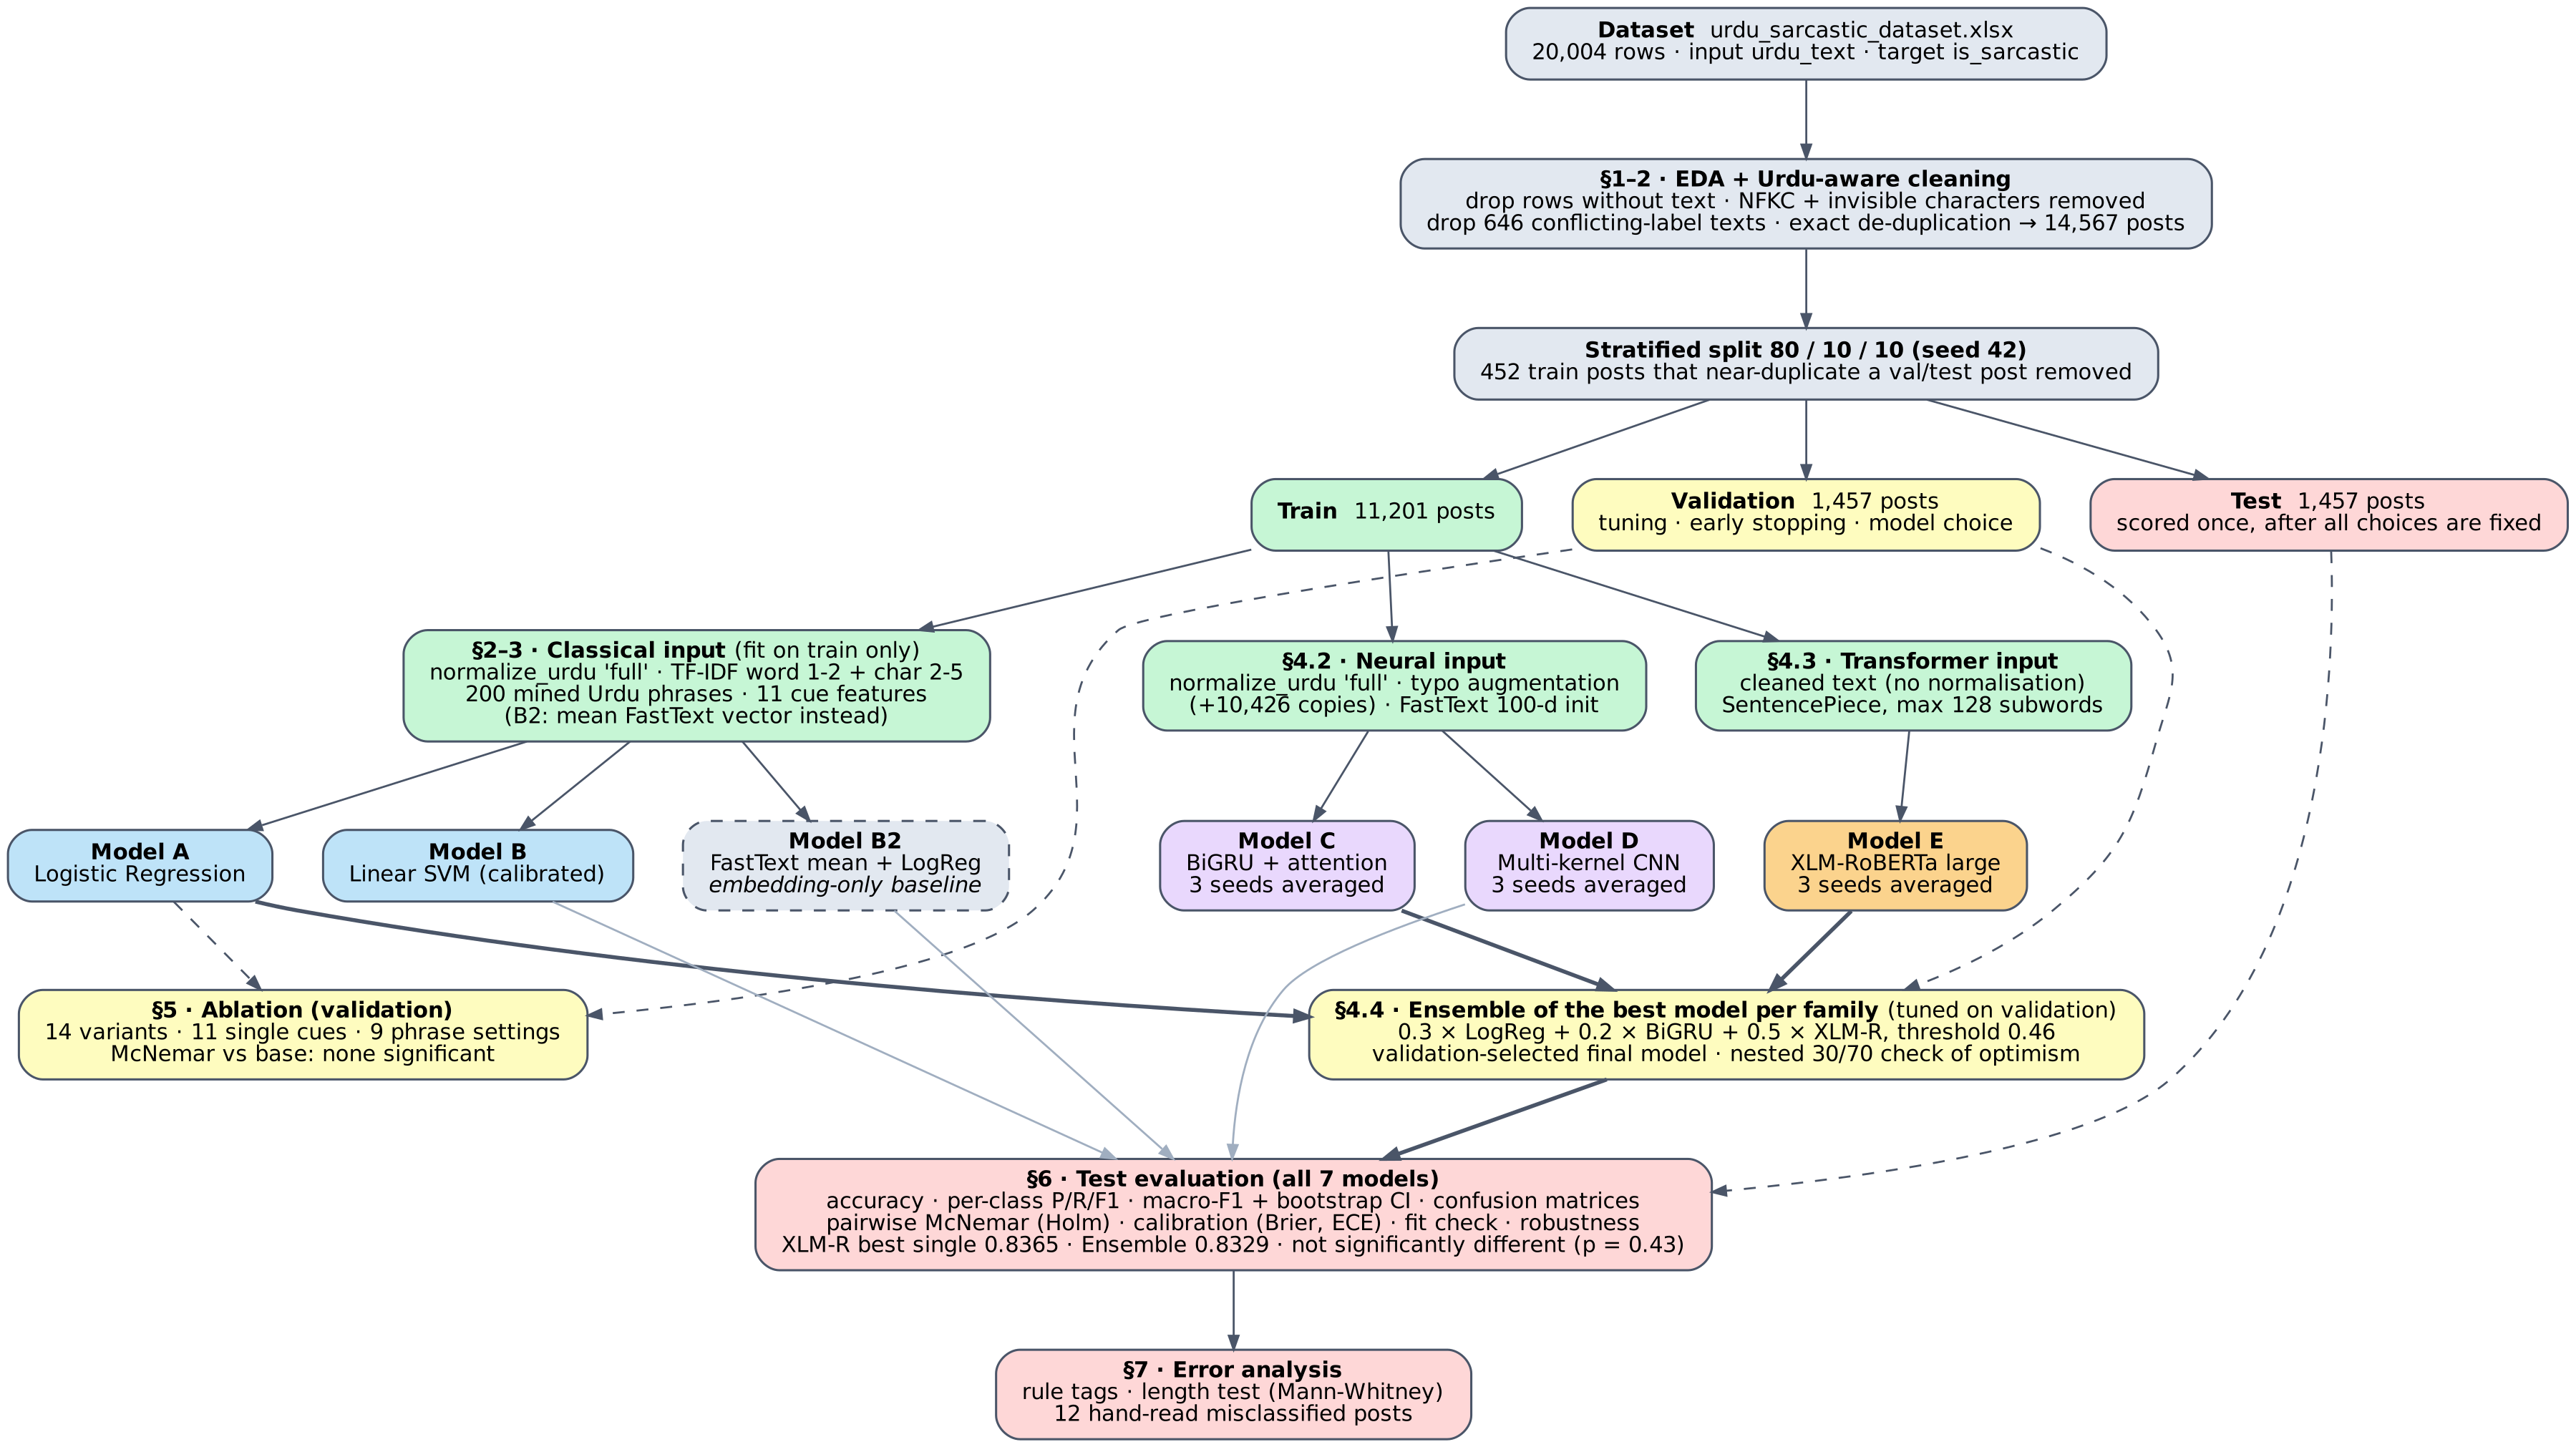

| Model | Input | Architecture | Training / selection |
|---|---|---|---|
| A Logistic Regression | TF-IDF word 1-2 + char_wb 2-5, 200 mined phrases, 11 cue features | linear, L2 | C and class weight tuned on validation |
| B Linear SVM | same as A | linear SVM + sigmoid calibration | C and class weight tuned on validation |
| C BiGRU + attention | ≤60 tokens, FastText 100-d init | BiGRU 2×128 → additive attention → dropout 0.3 → linear | Adam 1e-3, batch 64, early stopping (patience 3, max 15 epochs), 3 seeds averaged |
| D Multi-kernel CNN | same as C | Conv1d k = 2, 3, 4, 5 (128 filters each) → max-pool → dropout 0.3 → linear | same as C |
| E XLM-RoBERTa large | cleaned text, ≤128 subwords | pretrained encoder + classification head | lr 1e-5, warmup 10%, batch 16, ≤5 epochs, early stopping (patience 2), 3 seeds averaged |
| B2 FastText mean + LogReg (embedding-only baseline) | mean of FastText vectors | linear, L2 | C and class weight tuned on validation |
| Ensemble | probabilities of A, C, E (best per family) | weighted average | weights and threshold tuned on validation |


## Setup

All artifacts (splits, vectorizers, model weights, predictions, tables, figures) are saved under `PROJECT_DIR`.
With `RESUME = True`, finished neural and XLM-R runs can be loaded instead of retrained.

In [1]:
# Install the packages
%pip install -q gensim==4.4.0 arabic-reshaper==3.0.0 python-bidi==0.6.11 openpyxl==3.1.5

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 47.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 11.9 MB/s eta 0:00:00


In [2]:
# Imports
import os, re, sys, gc, math, json, random, unicodedata, itertools, urllib.request, platform
from functools import lru_cache
from pathlib import Path

import numpy as np, pandas as pd, scipy, scipy.sparse as sp
import matplotlib, matplotlib.pyplot as plt
from matplotlib import font_manager
import arabic_reshaper
from bidi.algorithm import get_display
import torch, torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
import gensim
from gensim.models import FastText
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.preprocessing import MaxAbsScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (f1_score, accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, log_loss)
from scipy.stats import binomtest
import joblib
import transformers
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

In [3]:
# Project folders
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = Path('/content/drive/MyDrive/Urdu_Sarcasm_Detection')
else:
    PROJECT_DIR = Path(os.environ.get('URDU_SARCASM_DIR', 'Urdu_Sarcasm_Detection'))

DIRS = {name: PROJECT_DIR / name for name in
        ['data',          # dataset file, split indices, augmented/typo text
         'classical',     # fitted vectorizers and linear models
         'neural',        # BiGRU / CNN state dicts and vocabulary
         'transformer',   # XLM-R checkpoints, tokenizers, per-run probabilities
         'results',       # predictions, metrics, tables
         'figures',       # plots and training histories
         'config']}       # experiment configuration and package versions
for folder in DIRS.values():
    folder.mkdir(parents=True, exist_ok=True)

# Experiment configuration
SEED = 42
RESUME = True # load finished neural / XLM-R runs instead of retraining
LABEL_NAMES = {0: 'non-sarcastic', 1: 'sarcastic'}
NEURAL = dict(max_len=60, emb_dim=100, hidden=128, dropout=0.3, lr=1e-3, batch=64,
              max_epochs=15, patience=3, seeds=[42, 43, 44])
XLMR = dict(models=['xlm-roberta-large', 'xlm-roberta-base'], # base only if every large run collapses
            seeds=[42, 43, 44, 45], n_good_runs=3, max_len=128, batch=16, lr=1e-5,
            weight_decay=0.01, warmup=0.1, max_epochs=5, patience=2)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

def set_seed(seed: int) -> None:
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def save_json(obj, path: Path) -> None:
    Path(path).write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=str), encoding='utf-8')

set_seed(SEED)
pd.set_option('display.max_colwidth', 110)
versions = {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
            'scipy': scipy.__version__, 'scikit-learn': sklearn.__version__, 'torch': torch.__version__,
            'transformers': transformers.__version__, 'gensim': gensim.__version__, 'matplotlib': matplotlib.__version__,
            'device': device, 'gpu': torch.cuda.get_device_name(0) if device == 'cuda' else None}
save_json(versions, DIRS['config'] / 'package_versions.json')
print('project folder:', PROJECT_DIR.resolve())
print(versions)

Mounted at /content/drive
project folder: /content/drive/MyDrive/Urdu_Sarcasm_Detection
{'python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.16.3', 'scikit-learn': '1.6.1', 'torch': '2.11.0+cpu', 'transformers': '5.18.0', 'gensim': '4.4.0', 'matplotlib': '3.10.0', 'device': 'cpu', 'gpu': None}


In [4]:
# Urdu letters in plots need a font that has them. matplotlib >= 3.11 shapes Arabic script itself; older versions need reshaping.
FONT = Path('NotoNaskhArabic-Regular.ttf')
try:
    if not FONT.exists():
        urllib.request.urlretrieve('https://raw.githubusercontent.com/notofonts/notofonts.github.io/main/'
                                   'fonts/NotoNaskhArabic/hinted/ttf/' + FONT.name, FONT)
    font_manager.fontManager.addfont(str(FONT))
    plt.rcParams['font.family'] = ['Noto Naskh Arabic', 'DejaVu Sans']
except OSError as err:   # plots still work, Urdu labels may then show as boxes
    print('Urdu font not available:', err)
NEW_MATPLOTLIB = tuple(int(v) for v in matplotlib.__version__.split('.')[:2]) >= (3, 11)

def ur(text: str) -> str:
    return text if NEW_MATPLOTLIB else get_display(arabic_reshaper.reshape(text))

def save_figure(fig, name: str) -> None:
    fig.savefig(DIRS['figures'] / name, dpi=150, bbox_inches='tight')

## 1. Exploratory Data Analysis

### 1.1 Loading and integrity checks

The loader checks that both required columns exist, that labels are binary and that the Urdu text is intact
(a non-UTF-8 CSV export turns Urdu letters into `?`; such a file is rejected rather than "repaired").

In [5]:
# Find the dataset, load it and run integrity checks
DATA_NAME = 'urdu_sarcastic_dataset'
ARABIC_SCRIPT = re.compile('[؀-ۿݐ-ݿﭐ-﷿ﹰ-﻿]')

def find_dataset() -> Path:
    for folder in [DIRS['data'], Path.cwd(), Path('/content')]:
        for pattern in (f'{DATA_NAME}*.xlsx', f'{DATA_NAME}*.csv'):
            hits = sorted(folder.glob(pattern))
            if hits:
                return hits[0]
    raise FileNotFoundError(f'{DATA_NAME}.xlsx not found.')

def load_raw(path: Path) -> pd.DataFrame:
    if path.suffix == '.xlsx':
        return pd.read_excel(path, sheet_name=0)
    return pd.read_csv(path, encoding='utf-8-sig')

def check_integrity(raw: pd.DataFrame) -> dict:
    missing_cols = {'urdu_text', 'is_sarcastic'} - set(raw.columns)
    if missing_cols:
        raise KeyError(f'required columns {missing_cols} missing; found {list(raw.columns)}')
    text = raw['urdu_text'].dropna().astype(str)
    no_script = ~text.str.contains(ARABIC_SCRIPT)
    question_heavy = text.str.count(r'\?') / text.str.len().clip(lower=1) > 0.3
    labels = pd.to_numeric(raw['is_sarcastic'], errors='coerce')
    report = {'rows': len(raw), 'missing text': int(raw['urdu_text'].isna().sum()),
              'missing label': int(raw['is_sarcastic'].isna().sum()),
              'non-binary labels': int((raw['is_sarcastic'].notna() & ~labels.isin([0, 1])).sum()),
              'posts without Arabic-script letters': int(no_script.sum()),
              'posts that look like "?"-corrupted Urdu': int((no_script & question_heavy).sum()),
              'posts with U+FFFD replacement character': int(text.str.contains('�').sum())}
    if (no_script & question_heavy).mean() > 0.01 or no_script.mean() > 0.2:
        raise ValueError('The Urdu text appears corrupted (letters replaced by "?" or missing).')
    return report

DATA_PATH = find_dataset()
raw = load_raw(DATA_PATH)
print('loaded:', DATA_PATH, '| shape:', raw.shape)
pd.Series(check_integrity(raw), name='value').to_frame()

loaded: /content/drive/MyDrive/Urdu_Sarcasm_Detection/data/urdu_sarcastic_dataset.xlsx | shape: (20004, 8)


,value
rows,20004
missing text,49
missing label,0
non-binary labels,0
posts without Arabic-script letters,0
"posts that look like ""?""-corrupted Urdu",0
posts with U+FFFD replacement character,1


In [6]:
# Inspect the stray "Unnamed" columns, then keep only the two required columns
stray = [c for c in raw.columns if c.startswith('Unnamed')]
print('non-empty cells in stray columns:', raw[stray].notna().sum().to_dict())
df = raw[['urdu_text', 'is_sarcastic']].copy()   # the stray columns are dropped here

non-empty cells in stray columns: {'Unnamed: 2': 0, 'Unnamed: 3': 0, 'Unnamed: 4': 0, 'Unnamed: 5': 0, 'Unnamed: 6': 17, 'Unnamed: 7': 38}


### 1.2 Class distribution, text length and data-quality issues
All numbers describe the raw file (before cleaning).

In [7]:
# Class counts, length statistics and data-quality counts on the raw file
text = df['urdu_text'].dropna().astype(str)
label = pd.to_numeric(df.loc[text.index, 'is_sarcastic'], errors='coerce').astype(int)
words = text.str.split().str.len()
print('class counts:', label.value_counts().to_dict())
stats = pd.DataFrame({'words': words, 'chars': text.str.len(), 'label': label})
print(stats.groupby('label').agg(['mean', 'median', 'max']).round(1))

print('\nexact duplicate rows:', text.duplicated().sum())
print('texts that appear with both labels:', (label.groupby(text).nunique() > 1).sum())
print('posts with zero-width characters:', text.str.contains('[​-‏‪-‮⁠-⁤﻿]').sum())
print('posts with a URL / @mention / #hashtag:', text.str.contains(r'http|www\.').sum(), text.str.contains('@').sum(), text.str.contains('#').sum())
print('posts with Latin letters (Roman Urdu / English):', text.str.contains('[A-Za-z]').sum())
tagged = text.str.contains('#sarcasm|#طنز', case=False)
print('posts with #sarcasm or #طنز:', tagged.sum(), '| share sarcastic:', round(label[tagged].mean(), 3))
laugh = text.str.contains('😂')
print('posts with 😂:', laugh.sum(), '| share sarcastic:', round(label[laugh].mean(), 3), '| overall share:', round(label.mean(), 3))

bucket = pd.cut(words, [0, 3, 10, 25, 10_000], labels=['1-3', '4-10', '11-25', '26+'])
pd.DataFrame({'posts': bucket.value_counts().sort_index(),
              'share sarcastic': label.groupby(bucket, observed=True).mean().round(3)})

class counts: {0: 9993, 1: 9962}
      words             chars            
       mean median max   mean median  max
label                                    
0      16.1   13.0  70   73.9   60.0  327
1      23.1   21.0  71  107.5   97.0  304

exact duplicate rows: 4689
texts that appear with both labels: 645
posts with zero-width characters: 296
posts with a URL / @mention / #hashtag: 379 772 756
posts with Latin letters (Roman Urdu / English): 2793
posts with #sarcasm or #طنز: 554 | share sarcastic: 0.991
posts with 😂: 5524 | share sarcastic: 0.573 | overall share: 0.499


,posts,share sarcastic
urdu_text,,
1-3,912,0.039
4-10,4117,0.248
11-25,10064,0.562
26+,4862,0.668


### 1.3 Label noise

In [8]:
# Label noise: identical posts should share a label, so count how often two identical posts disagree.
n_rows = label.groupby(text).size()
n_sarcastic = label.groupby(text).sum()
pairs = (n_rows * (n_rows - 1) / 2).sum()
disagree = (n_sarcastic * (n_rows - n_sarcastic)).sum()
rate = disagree / pairs
label_error = (1 - (1 - 2 * rate) ** 0.5) / 2   # solves 2e(1-e) = rate under symmetric, independent label noise
print(f'pairs of identical posts: {int(pairs)}, pairs with different labels: {int(disagree)} ({rate:.1%})')
print(f'implied label-error rate (rough, assumes symmetric independent noise): {label_error:.3f}')

pairs of identical posts: 8763, pairs with different labels: 1532 (17.5%)
implied label-error rate (rough, assumes symmetric independent noise): 0.097


### 1.4 Representative examples

In [9]:
# Three random posts per class
for lab in [1, 0]:
    print(f'--- label {lab} ({LABEL_NAMES[lab]}) examples ---')
    for t in text[label == lab].sample(3, random_state=SEED):
        print('*', t[:180])

--- label 1 (sarcastic) examples ---
* بالکل بالکل۔ پی ڈی ایم نے کہا تھا کہ ایسی غلیظ اور اخلاق سے گری ہوئی حرکت کرو۔ ایک آئی جی کو اغواء کرو۔ پرچہ کٹواو اور قوم کی بیٹی کے کمرے میں دروازہ توڑ کر گھس جاو۔ 👏👏👏
* زرداری کو مکار اور بزدل کہنا درست نہیں 😋😋
* کل تک پاک فوج کو گالیاں دے رہے تھے اور آج PDM پاک فوج سے انکوائری کی سفارش کر رہی ہے اسے کہتے ہیں تھوک کر چاٹنا
--- label 0 (non-sarcastic) examples ---
* اُسی ریاست کے اوپر والی ریاست نے نواز شریف کو کراچی جلسے میں تقریر نہ کرنے دی ۔۔ ظالم 😂
* کر لے مقابلہ، وہ بھی میں ہی جیتنا۔۔😎😎
* محترم باجوہ صاحب نے چال چل دی ہے اب انشاءاللہ مودی اور نیتن یاہو جنرل باجوہ صاحب کے بیٹ مین مقرر ہوں گے😂😂💖💖


### 1.5 Visualisation

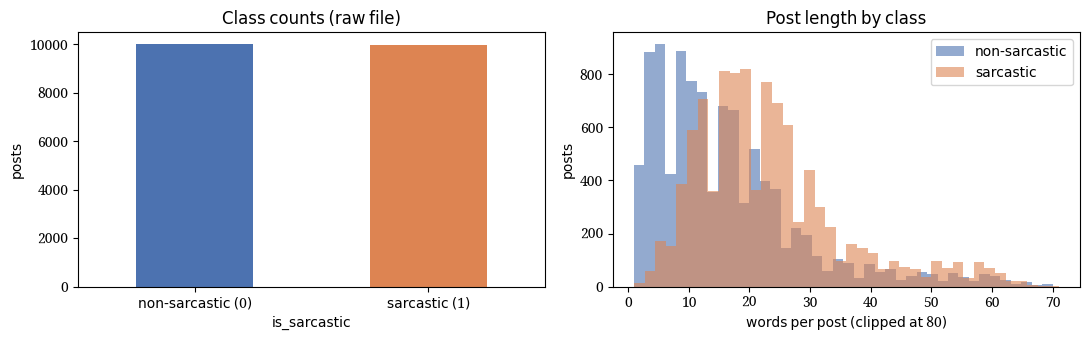

In [10]:
# Class balance and post length per class
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
label.value_counts().sort_index().plot.bar(ax=ax[0], color=['#4C72B0', '#DD8452'])
ax[0].set_xticklabels([f'{LABEL_NAMES[0]} (0)', f'{LABEL_NAMES[1]} (1)'], rotation=0)
ax[0].set_ylabel('posts'); ax[0].set_title('Class counts (raw file)')
for lab, color in [(0, '#4C72B0'), (1, '#DD8452')]:
    ax[1].hist(words[label == lab].clip(upper=80), bins=40, alpha=0.6, color=color, label=LABEL_NAMES[lab])
ax[1].set_xlabel('words per post (clipped at 80)'); ax[1].set_ylabel('posts'); ax[1].set_title('Post length by class'); ax[1].legend()
plt.tight_layout(); save_figure(fig, 'eda_class_length.png'); plt.show()

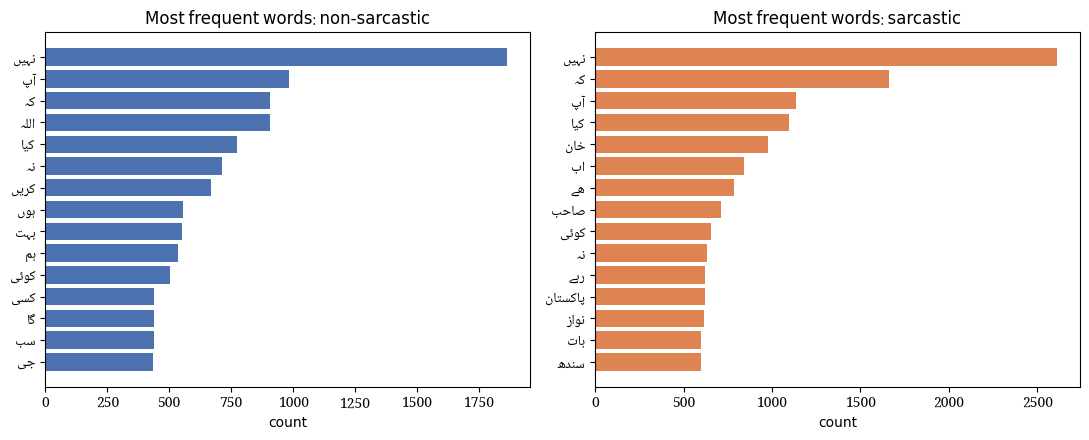

In [11]:
# Most frequent content words per class (function words hidden in this plot only)
STOP = set('کے کی ہے میں کا اور سے کو نے یہ ہیں تو بھی پر جو کر ہو وہ ایک تھا تھی گیا اس ہی'.split())   # plot only
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for k, lab in enumerate([0, 1]):
    tokens = [w for t in text[label == lab] for w in re.findall(r'\w+', t) if w not in STOP and len(w) > 1 and not w.isdigit()]
    top = pd.Series(tokens).value_counts().head(15)[::-1]
    ax[k].barh([ur(w) for w in top.index], top.values, color=['#4C72B0', '#DD8452'][k])
    ax[k].set_xlabel('count'); ax[k].set_title(f'Most frequent words: {LABEL_NAMES[lab]}')
plt.tight_layout(); save_figure(fig, 'eda_top_words.png'); plt.show()

Non-sarcastic posts cluster at short lengths; sarcastic posts are longer. The frequent words overlap heavily between the classes,
so single words separate them poorly.

### 1.6 EDA findings

- **Balance is misleading.** The raw file looks balanced (9,993 vs 9,962 after removing 49 rows without text), but it has 4,689 exact duplicate rows
  and 645 texts with both labels (646 after Unicode cleaning in 2.1). After cleaning the split is 59.4 / 40.6, so macro-F1 is the main metric.
- **Label noise.** Identical posts disagree in 17.5% of pairs; under a simple symmetric-noise model this implies about 10% wrong labels in the raw file.
- **Length.** Sarcastic posts are longer (23.1 vs 16.1 words on average); 1–3-word posts are only 3.9% sarcastic. Short posts are kept because length is a real signal.
- **Noise sources.** 296 posts contain zero-width characters, 379 URLs, 772 @mentions, 756 hashtags; 2,793 contain Latin letters (Roman Urdu / English code-mixing).
- **Collection artifact.** 554 posts contain `#sarcasm` or `#طنز` and 99.1% of them are sarcastic, so the tag partly reveals the label. They are kept and
  measured separately (hashtag ablation in 5, tag slice in 6.7).
- **Emojis.** 😂 appears in 5,524 posts; 57.3% of them are sarcastic vs 49.9% overall, so emojis carry some, but weak, signal.
- **Examples.** Sarcasm often appears as mock agreement (`بالکل بالکل` followed by a list of misdeeds and 👏👏👏).

## 2. Urdu-Aware Preprocessing

### 2.1 Cleaning and leakage-free stratified split

- **(a)** Drop rows with a missing post or a non-binary label.
- **(b)** NFKC-normalise and remove invisible characters. *Why: Urdu text mixes Arabic presentation forms (7 posts are written entirely in them) and zero-width joiners, so one post can exist as several strings.*
- **(c)** Remove every row of a post that occurs with both labels, then de-duplicate. *Why: a majority vote would keep a guess as ground truth; duplicates would leak across splits.*
- **(d)** Stratified 80/10/10 split (seed 42) after de-duplication. *Why: every split keeps the same class ratio (40.1–40.6% sarcastic).*
- **(e)** Remove training posts whose *core text* (no mentions, URLs, hashtags, punctuation, emojis, diacritics) equals a validation or test post. *Why: near-copies would inflate test scores.*

The original text is kept in `original_text`; models use the cleaned `text`.

In [12]:
# (a) drop invalid rows, (b) Unicode cleaning
steps = [('raw rows', len(df))]
df['is_sarcastic'] = pd.to_numeric(df['is_sarcastic'], errors='coerce')
df = df.dropna(subset=['urdu_text', 'is_sarcastic'])
df = df[df['is_sarcastic'].isin([0, 1])].copy()
df['is_sarcastic'] = df['is_sarcastic'].astype(int)
steps.append(('after dropping missing post / invalid label', len(df)))
labels_before_cleaning = df['is_sarcastic'].copy()

INVISIBLE = re.compile('[​-‏‪-‮⁠-⁤﻿�]')

def clean_unicode(text) -> str:
    """NFKC + invisible-character removal + whitespace collapse. Applied to every post, including new inputs at inference."""
    text = unicodedata.normalize('NFKC', str(text))
    text = INVISIBLE.sub('', text)
    return re.sub(r'\s+', ' ', text).strip()

df['text'] = df['urdu_text'].map(clean_unicode)
df = df[df['text'] != '']
steps.append(('after Unicode cleaning (empty posts dropped)', len(df)))

In [13]:
# (c) remove conflicting-label posts and exact duplicates
n_labels = df.groupby('text')['is_sarcastic'].nunique()
conflicts = set(n_labels[n_labels > 1].index)
print('conflicting texts:', len(conflicts), '| rows:', df['text'].isin(conflicts).sum())
df = df[~df['text'].isin(conflicts)]
steps.append(('after removing conflicting-label posts', len(df)))
df = (df.drop_duplicates('text')
        .rename(columns={'is_sarcastic': 'label', 'urdu_text': 'original_text'})[['text', 'original_text', 'label']]
        .reset_index(drop=True))
df.insert(0, 'id', range(len(df)))   # stable id per unique post
steps.append(('after exact de-duplication (unique posts)', len(df)))
assert len(conflicts) == 646 and len(df) == 14567, 'Counts differ from the supplied dataset; check the input file.'

def class_table(y: pd.Series) -> pd.DataFrame:
    counts = y.value_counts().sort_index()
    return pd.DataFrame({'count': counts, 'percent': (100 * counts / counts.sum()).round(1)}).rename(index=LABEL_NAMES)

pd.concat({'before cleaning': class_table(labels_before_cleaning), 'after cleaning': class_table(df['label'])}, axis=1)

conflicting texts: 646 | rows: 2131


before cleaning         after cleaning        
                        count percent          count percent
non-sarcastic            9993    50.1           8660    59.4
sarcastic                9962    49.9           5907    40.6

In [14]:
# (d) stratified 80/10/10 split, (e) near-duplicate purge from training
def core_text(text: str) -> str:
    """Post without mentions, URLs, hashtags, punctuation, emojis and diacritics; used to find near-duplicates."""
    text = re.sub(r'https?://\S+|www\.\S+|@\w+|#\w+', ' ', text)
    text = re.sub(r'[ً-ٰٟـ]', '', re.sub(r'[^\w\s]|_', ' ', text))
    return re.sub(r'\s+', ' ', text).strip().lower()

train_full, rest = train_test_split(df, test_size=0.2, stratify=df['label'], random_state=SEED)
val, test = train_test_split(rest, test_size=0.5, stratify=rest['label'], random_state=SEED)
assert (len(train_full), len(val), len(test)) == (11653, 1457, 1457)

held_out_cores = (set(val['text'].map(core_text)) | set(test['text'].map(core_text))) - {''}
near_dup = train_full['text'].map(core_text).isin(held_out_cores).values
val_test_overlap = (val['text'].map(core_text).isin(set(test['text'].map(core_text)) - {''})).sum()
print(f'training posts that near-duplicate a val/test post: {near_dup.sum()} ({near_dup.mean():.1%})')
print('val posts that near-duplicate a test post (left in place, val is only used for selection):', val_test_overlap)
train = train_full[~near_dup].copy()
steps.append(('training split after near-duplicate purge', len(train)))

for a, b in itertools.combinations([('train', train), ('val', val), ('test', test)], 2):
    assert not set(a[1]['text']) & set(b[1]['text']), f'{a[0]} and {b[0]} share posts'
print('split sizes:', {'train': len(train), 'val': len(val), 'test': len(test)})
print('sarcastic share per split:', {n: round(float(d['label'].mean()), 3) for n, d in [('train', train), ('val', val), ('test', test)]})

split_ids = pd.concat([train_full[['id']].assign(split=np.where(near_dup, 'train_purged', 'train')),
                       val[['id']].assign(split='val'), test[['id']].assign(split='test')])
split_ids.to_csv(DIRS['data'] / 'split_ids.csv', index=False)
df.to_csv(DIRS['data'] / 'clean_posts.csv', index=False)
cleaning = pd.DataFrame(steps, columns=['step', 'rows'])
cleaning.to_csv(DIRS['data'] / 'cleaning_steps.csv', index=False)
cleaning

training posts that near-duplicate a val/test post: 452 (3.9%)
val posts that near-duplicate a test post (left in place, val is only used for selection): 41
split sizes: {'train': 11201, 'val': 1457, 'test': 1457}
sarcastic share per split: {'train': 0.401, 'val': 0.406, 'test': 0.406}


,step,rows
0,raw rows,20004
1,after dropping missing post / invalid label,19955
2,after Unicode cleaning (empty posts dropped),19955
3,after removing conflicting-label posts,17824
4,after exact de-duplication (unique posts),14567
5,training split after near-duplicate purge,11201


Test posts have no exact duplicates, no conflicting labels and no near-duplicates in training. Removing conflicting posts means the hardest,
most ambiguous posts are absent from all splits, so test scores describe unambiguous posts.

### 2.2 Data augmentation (training split only)

One label-preserving copy of each training post gets one typo-style edit: letter elongation, adjacent-letter swap or dropped letter.
Two different posts can produce the same augmented string, so duplicate copies are dropped together with copies identical to an existing post and near-duplicates of a validation/test post; the cell below prints how many of each were dropped.

*Why: informal Urdu is spelled inconsistently, so typo copies teach the models to tolerate spelling variation.*

Augmentation is used by a family only if it improves validation macro-F1 (tested for the classical and neural models; XLM-R is trained on original posts only).

In [15]:
# Typo-style edits that keep the label: elongation, adjacent swap, dropped letter
MIN_LEN = {'elongation': 2, 'swap_adjacent': 4, 'drop_char': 5}

def edit_word(word: str, kind: str, rng: random.Random) -> str:
    if kind == 'elongation':        # drawn-out word: repeat the last letter once or twice
        return word + word[-1] * rng.choice([1, 2])
    if kind == 'swap_adjacent':     # typing error: swap two neighbouring inner letters
        i = rng.randrange(1, len(word) - 2)
        return word[:i] + word[i + 1] + word[i] + word[i + 2:]
    i = rng.randrange(1, len(word) - 1)   # drop_char: never the first or last letter
    return word[:i] + word[i + 1:]

def augment(text: str, rng: random.Random, kind: str | None = None):
    kind = kind or rng.choice(list(MIN_LEN))
    words = text.split(' ')
    candidates = [i for i, w in enumerate(words) if len(w) >= MIN_LEN[kind] and w.isalpha()]   # emojis, hashtags untouched
    if not candidates:
        return None, kind
    i = rng.choice(candidates)
    words[i] = edit_word(words[i], kind, rng)
    return ' '.join(words), kind

In [16]:
# One augmented copy per training post
rng = random.Random(SEED)
rows = []
for r in train.itertuples():
    new_text, kind = augment(r.text, rng)
    if new_text is not None:
        rows.append({'id': r.id, 'text': new_text, 'label': r.label, 'edit': kind})
train_aug = pd.DataFrame(rows)
n_made = len(train_aug)
train_aug = train_aug[~train_aug['text'].isin(set(df['text']))]   # equal to an existing post
n_existing = n_made - len(train_aug)
train_aug = train_aug.drop_duplicates('text')                      # two posts gave the same copy
n_duplicate = n_made - n_existing - len(train_aug)
train_aug = train_aug[~train_aug['text'].map(core_text).isin(held_out_cores)]   # near-duplicate of a val/test post
n_near = n_made - n_existing - n_duplicate - len(train_aug)
print(f'posts without an editable word: {len(train) - n_made} | copies made: {n_made} | dropped: {n_existing} equal to an existing post, '
      f'{n_duplicate} duplicate copies, {n_near} near-duplicates of val/test')
train_aug.to_csv(DIRS['data'] / 'train_augmented_copies.csv', index=False)
train_plus = pd.concat([train, train_aug], ignore_index=True)
print('augmented copies:', len(train_aug), train_aug['edit'].value_counts().to_dict())
for r in train_aug.head(3).itertuples():
    print(f'[{r.edit}]', train.loc[train.id == r.id, 'text'].iloc[0][:90], '\n   ->', r.text[:90])

posts without an editable word: 697 | copies made: 10504 | dropped: 76 equal to an existing post, 0 duplicate copies, 2 near-duplicates of val/test
augmented copies: 10426 {'elongation': 3800, 'swap_adjacent': 3547, 'drop_char': 3079}
[elongation] ـــــ•|💕~⛓|•ـــــ +خدایا لطــفا دلہایمان را به دلے که قسمتماݩ نیست نزدیک نکن ... قشنگ_ترین 
   -> ـــــ•|💕~⛓|•ـــــ +خدایا لطــفااا دلہایمان را به دلے که قسمتماݩ نیست نزدیک نکن ... قشنگ_تر
[elongation] ذرائع کے مطابق دورہ چین میں ملتی جلتی شکلوں کی وجہ سے خان کو کافی مسائل رہے ایک موقع پر مذ 
   -> ذرائع کے مطابق دورہ چین میں ملتی جلتی شکلوں کی وجہ سے خان کو کافیی مسائل رہے ایک موقع پر م
[drop_char] میرے آقا صلی اللّٰہ علیہ وسلم پر میری جان قربان 
   -> میرے آقا صلی اللّٰہ علیہ وسلم پر میری جان قربن


In [17]:
# TF-IDF helpers, then: does augmentation help the classical models? (validation)
TOKEN_PATTERN = r'(?u)\w+|[^\w\s]'   # words plus single symbols, so emojis and ?! stay tokens

def tfidf_blocks(word: bool = True, char: bool = True) -> list:
    blocks = []
    if word:
        blocks.append(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, token_pattern=TOKEN_PATTERN))
    if char:   # char n-grams still match when a word is spelled slightly differently
        blocks.append(TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), min_df=2, sublinear_tf=True))
    return blocks

def macro_f1(y, pred) -> float:
    return f1_score(y, pred, average='macro')

def tfidf_val_f1(train_df, val_df, model) -> float:
    blocks = tfidf_blocks()   # fitted on train_df only
    X_tr = sp.hstack([b.fit_transform(train_df['text']) for b in blocks]).tocsr()
    X_va = sp.hstack([b.transform(val_df['text']) for b in blocks]).tocsr()
    return macro_f1(val_df['label'], model.fit(X_tr, train_df['label']).predict(X_va))

def make_lr(C=4, weight=None):
    return LogisticRegression(C=C, class_weight=weight, max_iter=2000, solver='liblinear', random_state=SEED)

def make_svm(C=0.3, weight=None):
    return LinearSVC(C=C, class_weight=weight, random_state=SEED)

aug_rows = []
for name, make_model in [('LogReg (C=4)', make_lr), ('LinearSVC (C=0.3)', make_svm)]:
    aug_rows.append({'model': name, 'no augmentation': tfidf_val_f1(train, val, make_model()),
                     'with augmentation': tfidf_val_f1(train_plus, val, make_model())})
aug_table = pd.DataFrame(aug_rows).round(4)
USE_AUG = bool(aug_table['with augmentation'].mean() > aug_table['no augmentation'].mean())
fit_train = train_plus if USE_AUG else train
print('validation macro-F1, TF-IDF on raw text | classical models use augmentation:', USE_AUG)
aug_table

validation macro-F1, TF-IDF on raw text | classical models use augmentation: False


,model,no augmentation,with augmentation
0,LogReg (C=4),0.7922,0.7905
1,LinearSVC (C=0.3),0.7921,0.7912


In [18]:
# 500 test posts with one typo each, for the robustness check in Section 6.7 (text only, labels unused; built once).
rng = random.Random(SEED)
typo = test.sample(500, random_state=SEED)[['id', 'text']].copy()
for kind, col in [('drop_char', 'text_drop'), ('swap_adjacent', 'text_swap')]:
    typo[col] = [augment(t, rng, kind)[0] or t for t in typo['text']]   # posts with no long word stay unchanged
typo.to_csv(DIRS['data'] / 'test_typo_variants.csv', index=False)
print('posts changed by drop / swap:', (typo['text_drop'] != typo['text']).sum(), '/', (typo['text_swap'] != typo['text']).sum())

posts changed by drop / swap: 432 / 476


### 2.3 Urdu-aware normalisation

`normalize_urdu(text, mode)` runs on top of the Unicode cleaning:

| Mode | What it does |
|---|---|
| `raw` | nothing (minimal processing) |
| `light` | URLs → `URL`, @mentions → `USER` (their content is noise, their presence is not) |
| `full` | `light` + Arabic yeh/kaf → Urdu yeh/kaf, tatweel and diacritics removed, runs of 4+ identical characters cut to 3, `#` removed but the hashtag word kept, Latin letters lower-cased |


In [19]:
# Urdu normaliser with three modes
URL_RE = re.compile(r'https?://\S+|www\.\S+')
MENTION_RE = re.compile(r'@+\w+')
DIACRITICS = re.compile('[ـً-ٰٟ]')   # tatweel, harakat, superscript alef
REPEAT_RE = re.compile(r'(.)\1{3,}')
MODES = ['raw', 'light', 'full']

def normalize_urdu(text: str, mode: str = 'light') -> str:
    if mode not in MODES:
        raise ValueError(f'mode must be one of {MODES}')
    if mode == 'raw':
        return text
    text = MENTION_RE.sub('USER', URL_RE.sub('URL', text))
    if mode == 'full':
        text = text.replace('ي', 'ی').replace('ك', 'ک')   # Arabic yeh/kaf -> Urdu
        text = DIACRITICS.sub('', text)
        text = REPEAT_RE.sub(r'\1\1\1', text)
        text = text.replace('#', ' ')
        text = re.sub(r'[A-Za-z]+', lambda m: m.group().lower(), text)
        text = re.sub(r'\s+', ' ', text).strip()
    return text

def with_mode(d: pd.DataFrame, mode: str) -> pd.DataFrame:
    return d.assign(text=d['text'].map(lambda t: normalize_urdu(t, mode)))

In [20]:
# Show the three modes on one post and choose the mode on validation
demo = train['text'][train['text'].str.contains('@') & train['text'].str.contains('[ً-ٟ]')].iloc[0]
for m in MODES:
    print(f'{m:>5}:', normalize_urdu(demo, m)[:160])

mode_scores = {m: tfidf_val_f1(with_mode(fit_train, m), with_mode(val, m), make_lr()) for m in MODES}
MODE = max(mode_scores, key=mode_scores.get)
print('\nvalidation macro-F1 by mode:', {m: round(s, 4) for m, s in mode_scores.items()}, '| chosen:', MODE)

  raw: @AneesaCh_ لیکن کراچی والے تنقید پھر بھی پی ٹی آئی گورمِٹ پر ہـــــــــــی کرتے ہیں 😐
light: USER لیکن کراچی والے تنقید پھر بھی پی ٹی آئی گورمِٹ پر ہـــــــــــی کرتے ہیں 😐
 full: user لیکن کراچی والے تنقید پھر بھی پی ٹی آئی گورمٹ پر ہی کرتے ہیں 😐

validation macro-F1 by mode: {'raw': 0.7922, 'light': 0.7908, 'full': 0.7961} | chosen: full


`full` scores highest on validation (0.7961 vs 0.7922 `raw` and 0.7908 `light`) and is used by Models A–D. This is a selection rule, not a finding: the ablation in Section 5 tests the modes with the tuned model and finds no significant difference.

## 3. Feature Engineering

The classical models combine four feature groups, all fitted on the training split only:

1. **TF-IDF word 1–2-grams** with a tokenizer that keeps each emoji, `!` and `?` as a token. *Why: word pairs capture short sarcastic patterns.*
2. **TF-IDF character 2–5-grams** (`char_wb`). *Why: they still match when an Urdu or Roman-Urdu word is spelled differently.*
3. **Mined Urdu phrases** (Section 3.1).
4. **Sarcasm cue features** (Section 3.2).

An extra **Urdu sarcasm-marker lexicon** (Section 3.3) is evaluated as an additional experiment.

### 3.1 Mined Urdu phrases

The 100 most sarcastic and 100 most non-sarcastic word bigrams/trigrams are mined from the **training split only** with a smoothed log-odds ratio
and used as binary features. Phrases are mined from **original posts only** (augmented copies are excluded via the `edit` column), so a typo copy cannot count the same phrase twice and inflate its score; with the final setting the classical models use no augmentation, so all training posts are original. *Why: Urdu sarcasm often sits in stock phrases (`واہ کیا بات ہے`, `بہت خوب`) rather than single words.*

In [21]:
# Mine class-distinctive bigrams/trigrams with a smoothed log-odds ratio
WORD_PATTERN = r'(?u)\w+'

def mine_phrases(texts, labels, k: int = 100, min_count: int = 5, alpha: float = 0.5):
    cv = CountVectorizer(ngram_range=(2, 3), token_pattern=WORD_PATTERN, binary=True, min_df=min_count)
    X = cv.fit_transform(texts)
    y = np.asarray(labels)
    n1, n0 = (y == 1).sum(), (y == 0).sum()
    c1, c0 = np.asarray(X[y == 1].sum(0)).ravel(), np.asarray(X[y == 0].sum(0)).ravel()
    score = np.log((c1 + alpha) / (n1 - c1 + alpha)) - np.log((c0 + alpha) / (n0 - c0 + alpha))   # smoothed log-odds ratio
    order, names = np.argsort(score), cv.get_feature_names_out()
    return list(names[order[::-1][:k]]), list(names[order[:k]])

### 3.2 Sarcasm cue features

Eleven counts: emojis, `!`, `?`/`؟`, ellipses (`…`, `...`, `۔۔`), repeated-character runs, share of Latin words (code-mixing), words inside quotes,
URL / mention / hashtag presence and log word count. They read the cleaned, un-normalised text.
*Why: tone in short posts lives in punctuation, emojis, stretching and quoting, which TF-IDF weights only indirectly.*

In [22]:
# Eleven surface cues of sarcastic tone
EMOJI = re.compile('[\U0001F000-\U0001FAFF☀-➿⬀-⯿]')
ELLIPSIS = re.compile(r'…|\.{2,}|۔{2,}')
QUOTED = re.compile(r"(?:``|\"|“|‘)(.+?)(?:''|\"|”|’)")
CUE_NAMES = ['emoji', 'exclaim', 'question', 'ellipsis', 'char_runs', 'latin_ratio',
             'quoted_words', 'url', 'mention', 'hashtag', 'log_words']

def cue_vector(text: str) -> list:
    words = text.split()
    latin = sum(bool(re.search('[A-Za-z]', w)) for w in words)
    return [len(EMOJI.findall(text)), text.count('!'), text.count('?') + text.count('؟'),
            len(ELLIPSIS.findall(text)), len(re.findall(r'(.)\1{2,}', text)), latin / max(len(words), 1),
            sum(len(q.split()) for q in QUOTED.findall(text)), int('http' in text or 'www.' in text),
            int('@' in text), int('#' in text), math.log1p(len(words))]

def cue_matrix(texts) -> np.ndarray:
    return np.array([cue_vector(t) for t in texts], dtype=float)

### 3.3 Urdu sarcasm-marker lexicon (extra experiment)

Hand-written Urdu (and common Roman-Urdu) markers grouped by function: mock praise (`واہ`, `شاباش`, `کیا بات ہے`), mock agreement (`بالکل`, `جی جی`),
mock respect (`صاحب`, `جناب`, `محترم`), laughter (`ہاہا`, `ھاھا`), contrast (`لیکن`, `مگر`), intensifiers (`بہت`, `انتہائی`), negation (`نہیں`, `مت`, `ناں`),
plus a rhetorical-question flag (question word such as `کیا`/`کیوں` together with `?`/`؟`). Matching runs after `full` normalisation, so Arabic/Urdu
letter variants match. *Why: these are the linguistic devices Urdu speakers use to signal irony; unlike mined phrases they do not depend on the corpus.*
The `#sarcasm`/`#طنز` tags are deliberately excluded because they are collection artifacts.

In [23]:
# Hand-written Urdu sarcasm-marker lexicon (counts per marker group + rhetorical-question flag)
URDU_MARKERS = {
    'mock_praise':    ['واہ', 'شاباش', 'کمال', 'زبردست', 'بہت خوب', 'کیا بات ہے', 'کیا کہنے', 'سبحان اللہ', 'ماشاءاللہ', 'ماشااللہ', 'wah', 'shabash', 'kamal'],
    'mock_agreement': ['بالکل', 'جی جی', 'جی ہاں', 'ہاں جی', 'یقینا', 'یقیناً', 'bilkul'],
    'mock_respect':   ['صاحب', 'جناب', 'محترم', 'حضرت', 'سرکار'],
    'laughter':       ['ہاہا', 'ہا ہا', 'ھاھا', 'ہی ہی', 'haha', 'hahaha', 'lol'],
    'contrast':       ['لیکن', 'مگر', 'البتہ', 'ورنہ', 'پھر بھی', 'حالانکہ'],
    'intensifier':    ['بہت', 'انتہائی', 'بےحد', 'بے حد', 'سب سے'],
    'negation':       ['نہیں', 'نہ', 'مت', 'ناں']}
QUESTION_WORDS = ['کیا', 'کیوں', 'کیسے', 'کون', 'کب', 'کہاں']
LEXICON_NAMES = list(URDU_MARKERS) + ['rhetorical_question']

def marker_regex(terms: list) -> re.Pattern:
    terms = sorted({normalize_urdu(t, 'full') for t in terms}, key=len, reverse=True)   # longest match first
    return re.compile(r'(?<!\w)(?:' + '|'.join(map(re.escape, terms)) + r')(?!\w)')   # whole words only

MARKER_RE = {group: marker_regex(terms) for group, terms in URDU_MARKERS.items()}
QUESTION_RE = marker_regex(QUESTION_WORDS)

def lexicon_vector(text: str) -> list:
    t = normalize_urdu(text, 'full')   # unify Arabic/Urdu letter variants before matching
    rhetorical = int(bool(QUESTION_RE.search(t)) and ('?' in t or '؟' in t))
    return [len(r.findall(t)) for r in MARKER_RE.values()] + [rhetorical]

def lexicon_matrix(texts) -> np.ndarray:
    return np.array([lexicon_vector(t) for t in texts], dtype=float)

### 3.4 What the engineered features capture (training split)

In [24]:
# Top mined phrases per class and mean cue values per class
sarcastic_phrases, plain_phrases = mine_phrases(with_mode(train, MODE)['text'], train['label'])
print('top sarcastic phrases:    ', ' | '.join(sarcastic_phrases[:12]))
print('top non-sarcastic phrases:', ' | '.join(plain_phrases[:12]))
pd.DataFrame(cue_matrix(train['text']), columns=CUE_NAMES).groupby(train['label'].values).mean().rename(index=LABEL_NAMES).round(3)

top sarcastic phrases:     حس مزاح | و مزاح | طنز و | طنز و مزاح | ہے sarcasm | مزاح کے | شہباز شریف | مزاح کا | مزاح کی | کی حس مزاح | مزاح میں | طنز url
top non-sarcastic phrases: فالو کریں | کو فالو کریں | مینشن کریں | فالو کریں اور | والوں کو فالو | کا اضافہ | خاتم_النبیین_محمدصلى الله علیه | فالورز کا | خاتم_النبیین_محمدصلى الله | فالورز کا اضافہ | کریں اور فالو | اور فالو


,emoji,exclaim,question,ellipsis,char_runs,latin_ratio,quoted_words,url,mention,hashtag,log_words
non-sarcastic,2.318,0.002,0.057,0.234,0.394,0.007,0.085,0.002,0.008,0.003,2.594
sarcastic,1.686,0.029,0.100,0.220,0.319,0.024,0.260,0.060,0.116,0.124,3.088


In [25]:
# Mean lexicon-marker counts per class
pd.DataFrame(lexicon_matrix(train['text']), columns=LEXICON_NAMES).groupby(train['label'].values).mean().rename(index=LABEL_NAMES).round(3)

,mock_praise,mock_agreement,mock_respect,laughter,contrast,intensifier,negation,rhetorical_question
non-sarcastic,0.034,0.008,0.038,0.003,0.045,0.066,0.276,0.018
sarcastic,0.025,0.010,0.086,0.005,0.097,0.050,0.359,0.034


- The mined phrases expose **collection artifacts** as well as real cues: `طنز و مزاح` (satire and humour), `حس مزاح` and `sarcasm` rank as sarcastic,
  follow-requests (`فالو کریں`) and religious formulae as non-sarcastic. The hashtag ablation (Section 5) measures the reliance on them.
- Cue means: sarcastic posts have more `!`, `?`, quoted words, URLs, mentions, hashtags and Latin words and are longer; non-sarcastic posts have **more** emojis on average.
- Lexicon means: negation (0.359 vs 0.276), contrast (0.097 vs 0.045), mock respect (0.086 vs 0.038) and rhetorical questions (0.034 vs 0.018) are more
  frequent in sarcastic posts; mock praise and intensifiers are *less* frequent (they are mostly used sincerely), so single markers are weak cues on their own.

### 3.5 Feature assembly and contribution

In [26]:
# Fit all feature blocks on training data only and turn texts into one sparse matrix
def fit_features(train_df, mode, word=True, char=True, phrases=True, cues=True, lexicon=False) -> dict:
    """Fit every learned feature block on train_df only."""
    text = [normalize_urdu(t, mode) for t in train_df['text']]
    feats = {'mode': mode, 'tfidf': tfidf_blocks(word, char), 'phrases': None, 'scaler': None}
    for block in feats['tfidf']:
        block.fit(text)
    if phrases:   # mined from original posts only, so augmented copies do not count a phrase twice
        original = train_df['edit'].isna().values if 'edit' in train_df else np.ones(len(train_df), dtype=bool)
        sarcastic, plain = mine_phrases(np.array(text)[original], train_df['label'].values[original])
        feats['phrases'] = CountVectorizer(vocabulary=list(dict.fromkeys(sarcastic + plain)), ngram_range=(2, 3),
                                           token_pattern=WORD_PATTERN, binary=True)
    if cues:
        feats['scaler'] = MaxAbsScaler().fit(cue_matrix(train_df['text']))
    if lexicon:   # optional Urdu marker lexicon (Section 3.3); off in the final pipeline
        feats['lexicon'] = MaxAbsScaler().fit(lexicon_matrix(train_df['text']))
    return feats

def transform(feats: dict, texts) -> sp.csr_matrix:
    texts = list(texts)
    normalized = [normalize_urdu(t, feats['mode']) for t in texts]
    parts = [block.transform(normalized) for block in feats['tfidf']]
    if feats['phrases'] is not None:
        parts.append(feats['phrases'].transform(normalized))
    if feats['scaler'] is not None:
        parts.append(sp.csr_matrix(feats['scaler'].transform(cue_matrix(texts))))   # cues read the cleaned, un-normalised text
    if feats.get('lexicon') is not None:
        parts.append(sp.csr_matrix(feats['lexicon'].transform(lexicon_matrix(texts))))
    return sp.hstack(parts).tocsr()

def val_score(train_df, val_df, model, **options) -> float:
    feats_ = fit_features(train_df, **options)
    model.fit(transform(feats_, train_df['text']), train_df['label'])
    return macro_f1(val_df['label'], model.predict(transform(feats_, val_df['text'])))

In [27]:
# Contribution of each engineered feature group (untuned LogReg C=4, validation macro-F1)
gain = {name: val_score(fit_train, val, make_lr(), mode=MODE, phrases=p, cues=c, lexicon=l)
        for name, p, c, l in [('TF-IDF only', False, False, False), ('+ cues', False, True, False),
                              ('+ phrases', True, False, False), ('+ lexicon', False, False, True),
                              ('+ phrases + cues (final setup)', True, True, False),
                              ('+ phrases + cues + lexicon', True, True, True)]}
gain_table = pd.DataFrame({'val_macro_f1': gain}).round(4)
gain_table['gain_vs_tfidf'] = (gain_table['val_macro_f1'] - gain['TF-IDF only']).round(4)
gain_table.to_csv(DIRS['results'] / 'feature_gain_validation.csv')
gain_table

,val_macro_f1,gain_vs_tfidf
TF-IDF only,0.7961,0.0000
+ cues,0.7952,-0.0009
+ phrases,0.7951,-0.0010
+ lexicon,0.7983,0.0022
+ phrases + cues (final setup),0.7973,0.0012
+ phrases + cues + lexicon,0.7959,-0.0002


The final setup uses TF-IDF + phrases + cues (+0.0012). Every engineered group changes validation macro-F1 by less than 0.003, well inside the ±0.02 noise of a
1,457-post validation set: the character n-grams already capture most phrase and cue information. The lexicon alone adds +0.0022 to TF-IDF but nothing on top of
phrases + cues (0.7959 with it vs 0.7973 without; untuned, not tested for significance), so it is reported but **not** added to the final pipeline; its effect with the tuned model is in the ablation (Section 5).

## 4. Model Training

### 4.1 Traditional Models (TF-IDF)

Both models use the Section 3 features (about 105k sparse columns for 11,201 training posts).
*Why linear models: they are the standard strong baseline for high-dimensional sparse text features and train in seconds.*
`C` and `class_weight` are tuned on validation macro-F1; `balanced` is kept only if it wins. Comparisons between models use the exact McNemar test defined below.

In [28]:
# Build the training and validation feature matrices and a small tuning helper
feats = fit_features(fit_train, MODE)
X_train, X_val = transform(feats, fit_train['text']), transform(feats, val['text'])
y_train, y_val = fit_train['label'].values, val['label'].values
print('training matrix:', X_train.shape, '| augmentation:', USE_AUG, '| mode:', MODE)

def tune(make_model, c_values):
    results, best = [], None
    for C, weight in itertools.product(c_values, [None, 'balanced']):
        f1 = macro_f1(y_val, make_model(C, weight).fit(X_train, y_train).predict(X_val))
        results.append((C, weight or 'none', round(f1, 4)))
        if best is None or f1 > best[0]:
            best = (f1, C, weight)
    print(pd.DataFrame(results, columns=['C', 'class_weight', 'val_macro_f1']).pivot(index='C', columns='class_weight', values='val_macro_f1'))
    return best[1], best[2]

training matrix: (11201, 104814) | augmentation: False | mode: full


In [29]:
# Exact McNemar test: are two classifiers' error rates on the same posts different?
def mcnemar_p(y, pred_a, pred_b) -> tuple:
    a_ok, b_ok = np.asarray(pred_a) == y, np.asarray(pred_b) == y
    only_a, only_b = int((a_ok & ~b_ok).sum()), int((~a_ok & b_ok).sum())   # discordant pairs
    p = binomtest(only_a, only_a + only_b, 0.5).pvalue if only_a + only_b else 1.0
    return only_a, only_b, p

#### Model A: Logistic Regression

In [30]:
# Model A: tune C and class weight on validation, then fit
lr_C, lr_weight = tune(make_lr, [1, 2, 4, 8])
lr_model = make_lr(lr_C, lr_weight).fit(X_train, y_train)
print('best: C =', lr_C, '| class_weight =', lr_weight)

class_weight  balanced    none
C                             
1               0.8083  0.8003
2               0.8025  0.7984
4               0.7934  0.7973
8               0.7946  0.7886
best: C = 1 | class_weight = balanced


#### Model B: Linear SVM

In [31]:
# Model B: tune C and class weight; sigmoid calibration only turns SVM scores into probabilities for the ensemble
svm_C, svm_weight = tune(make_svm, [0.1, 0.3, 1.0])
svm_model = CalibratedClassifierCV(make_svm(svm_C, svm_weight), method='sigmoid', cv=3).fit(X_train, y_train)
print('best: C =', svm_C, '| class_weight =', svm_weight)

class_weight  balanced    none
C                             
0.1             0.8084  0.7974
0.3             0.7950  0.7966
1.0             0.7867  0.7833
best: C = 0.1 | class_weight = balanced


#### Classical model selection, fit check and feature weights

In [32]:
# Validation macro-F1 of both classical models; save them
classical = {'LogReg': lr_model, 'LinearSVC': svm_model}
val_probs = {name: model.predict_proba(X_val)[:, 1] for name, model in classical.items()}
classical_f1 = {name: macro_f1(y_val, p >= 0.5) for name, p in val_probs.items()}
best_classical = max(classical_f1, key=classical_f1.get)
joblib.dump({'features': feats, 'models': classical, 'best': best_classical, 'mode': MODE},
            DIRS['classical'] / 'classical_models.joblib')
print('validation macro-F1:', {n: round(f, 4) for n, f in classical_f1.items()}, '| best classical:', best_classical)

validation macro-F1: {'LogReg': 0.8083, 'LinearSVC': 0.8083} | best classical: LogReg


In [33]:
# Fit check: training vs validation macro-F1
fit_table = pd.DataFrame({name: {'train_macro_f1': macro_f1(y_train, m.predict(X_train)), 'val_macro_f1': macro_f1(y_val, m.predict(X_val))}
                          for name, m in classical.items()}).T
fit_table['gap'] = fit_table['train_macro_f1'] - fit_table['val_macro_f1']
fit_table.round(4)

,train_macro_f1,val_macro_f1,gap
LogReg,0.9197,0.8083,0.1114
LinearSVC,0.8939,0.8083,0.0856


In [34]:
# Largest Model A weights among the engineered Urdu features (phrases and cues)
n_tfidf = sum(len(block.vocabulary_) for block in feats['tfidf'])
eng_names = [f'phrase: {p}' for p in feats['phrases'].get_feature_names_out()] + [f'cue: {c}' for c in CUE_NAMES]
assert n_tfidf + len(eng_names) == X_train.shape[1]   # column order: word, char, phrases, cues
eng_weights = pd.Series(lr_model.coef_[0][n_tfidf:], index=eng_names)
pd.DataFrame({'towards sarcastic': eng_weights.nlargest(10).index, 'weight': eng_weights.nlargest(10).values.round(3),
              'towards non-sarcastic': eng_weights.nsmallest(10).index, 'weight ': eng_weights.nsmallest(10).values.round(3)})

,towards sarcastic,weight,towards non-sarcastic,weight
0,cue: log_words,4.388,phrase: اور بھی,-1.658
1,cue: hashtag,2.616,cue: emoji,-1.434
2,phrase: حس مزاح,1.371,phrase: رضی اللہ,-1.093
3,cue: mention,1.322,phrase: کو فالو,-0.988
4,phrase: پر ڈال,1.319,phrase: فالو بیک,-0.823
5,phrase: نیو خان,1.295,phrase: تجھ سے,-0.774
6,phrase: یہ وہ,1.272,phrase: فالو کریں,-0.754
7,phrase: لیکن کچھ,1.235,phrase: ٹویٹ کو,-0.726
8,phrase: مراد علی شاہ,1.215,phrase: علیه وسلم,-0.666
9,phrase: 22 کروڑ,1.170,phrase: محبت کے,-0.661


Training macro-F1 is about 0.1 above validation for both models, the usual gap for linear models on ~105k sparse features; the small `C`
(strong regularisation) chosen on validation keeps it in check, and validation and test scores agree (Section 6.6).
Among the engineered features, post length, hashtag and mention cues, the collection phrase `حس مزاح` and political names (`مراد علی شاہ`, `22 کروڑ`)
push towards sarcastic; emoji count, follow-requests (`فالو کریں`, `فالو بیک`) and religious formulae (`رضی اللہ`, `علیه وسلم`) push towards non-sarcastic.

#### Model B2: embedding-only baseline

Each post is the **mean of its FastText vectors** (same tokens and FastText settings as Section 4.2, trained on the training split only), classified by Logistic Regression.
*Why: compared with Model A it isolates the value of the sparse TF-IDF/phrase/cue features; compared with Models C and D it isolates the value of sequence modelling.*
The comparison with C/D is not fully controlled: the networks also fine-tune their embeddings and train on augmented posts.

In [35]:
# Model B2: mean FastText vector per post + Logistic Regression (no TF-IDF, no word order)
from sklearn.preprocessing import StandardScaler

def b2_tokens(text: str) -> list:
    return re.findall(TOKEN_PATTERN, normalize_urdu(text, MODE))   # same tokens as the neural models

b2_ft = FastText(sentences=[b2_tokens(t) for t in fit_train['text']], vector_size=NEURAL['emb_dim'],
                 window=5, min_count=2, epochs=10, seed=SEED, workers=1)   # same settings as Section 4.2, training split only

def b2_matrix(texts) -> np.ndarray:
    out = np.zeros((len(texts), b2_ft.vector_size), dtype=np.float32)
    for i, t in enumerate(texts):
        tokens = b2_tokens(t)
        if tokens:
            out[i] = np.mean([b2_ft.wv[w] for w in tokens], axis=0)   # subword n-grams also give unseen words a vector
    return out

b2_scaler = StandardScaler().fit(b2_matrix(list(fit_train['text'])))
B2_train = b2_scaler.transform(b2_matrix(list(fit_train['text'])))
B2_val = b2_scaler.transform(b2_matrix(list(val['text'])))

b2_grid = []
for C, weight in itertools.product([0.01, 0.1, 1, 10], [None, 'balanced']):
    f1 = macro_f1(y_val, LogisticRegression(C=C, class_weight=weight, max_iter=2000, random_state=SEED).fit(B2_train, y_train).predict(B2_val))
    b2_grid.append((C, weight or 'none', round(f1, 4)))
print(pd.DataFrame(b2_grid, columns=['C', 'class_weight', 'val_macro_f1']).pivot(index='C', columns='class_weight', values='val_macro_f1'))
b2_C, b2_weight, b2_val_f1 = max(b2_grid, key=lambda r: r[2])
b2_model = LogisticRegression(C=b2_C, class_weight=None if b2_weight == 'none' else b2_weight, max_iter=2000, random_state=SEED).fit(B2_train, y_train)
b2_val_pred = b2_model.predict(B2_val)
only_a, only_b, p = mcnemar_p(y_val, lr_model.predict(X_val), b2_val_pred)
print(f'\nB2 best: C = {b2_C}, class_weight = {b2_weight} | validation macro-F1 {b2_val_f1:.4f} vs Model A {macro_f1(y_val, lr_model.predict(X_val)):.4f}')
print(f'McNemar Model A vs B2 (validation): only A right = {only_a}, only B2 right = {only_b}, p = {p:.4g}')

class_weight  balanced    none
C                             
0.01            0.7517  0.7580
0.10            0.7582  0.7680
1.00            0.7608  0.7679
10.00           0.7671  0.7668

B2 best: C = 0.1, class_weight = none | validation macro-F1 0.7680 vs Model A 0.8083
McNemar Model A vs B2 (validation): only A right = 137, only B2 right = 83, p = 0.0003313


B2 reaches validation macro-F1 **0.7680** (best C = 0.1, no class weight), 0.0403 below Model A (0.8083). The exact McNemar test on validation is significant
(only A right 137, only B2 right 83, p = 0.00033): averaging FastText vectors loses the word-pair, phrase and character-pattern information that the TF-IDF model uses.
B2's test score is in Section 6.2 and its comparisons with the other models in Section 6.5.

### 4.2 Neural Models

Both networks start from **FastText** vectors trained on the training text only.

*Why FastText: it builds word vectors from character n-grams, so stretched words, misspellings and Roman-Urdu tokens get vectors close to their usual forms.*

Training: Adam (lr 1e-3), batch 64, cross-entropy, early stopping on validation macro-F1 (patience 3, max 15 epochs, best weights restored).

*Why three seeds averaged: single runs vary between seeds; averaging gives a stable model.* No class weighting is used for the networks.

#### Shared components: early stopping, tokenisation, embeddings

In [36]:
# Early stopping on validation macro-F1 with a CPU copy of the best weights
class EarlyStopping:
    """Stops when the monitored score has not improved for `patience` epochs and keeps a CPU copy of the best weights."""
    def __init__(self, patience: int, min_delta: float = 0.0, half_precision: bool = False):
        self.patience, self.min_delta, self.half = patience, min_delta, half_precision
        self.best_score, self.best_epoch, self.best_state, self.wait = -np.inf, 0, None, 0

    def step(self, score: float, epoch: int, model: nn.Module) -> bool:
        if score > self.best_score + self.min_delta:
            self.best_score, self.best_epoch, self.wait = score, epoch, 0
            self.best_state = {k: (v.detach().to('cpu', copy=True).half() if self.half and v.is_floating_point()
                                   else v.detach().to('cpu', copy=True)) for k, v in model.state_dict().items()}
            return False
        self.wait += 1
        return self.wait >= self.patience

    def restore(self, model: nn.Module) -> nn.Module:
        model.load_state_dict(self.best_state)   # load_state_dict casts back to the model's dtype
        return model

In [37]:
# Tokeniser (each emoji/symbol is a token), training-only vocabulary and FastText embedding matrix
def tokenize(text: str) -> list:
    return re.findall(r'\w+|[^\w\s]', text)   # every emoji or symbol is its own token

def prepare_neural(train_df):
    """Vocabulary and FastText embedding matrix, both from the training posts only."""
    tokens = [tokenize(normalize_urdu(t, MODE)) for t in train_df['text']]
    ft = FastText(sentences=tokens, vector_size=NEURAL['emb_dim'], window=5, min_count=2, epochs=10, seed=SEED, workers=1)
    vocab = {'<pad>': 0, '<unk>': 1}
    for sentence in tokens:
        for token in sentence:
            vocab.setdefault(token, len(vocab))
    emb = np.zeros((len(vocab), NEURAL['emb_dim']), dtype=np.float32)
    for token, i in vocab.items():
        if i >= 2:
            emb[i] = ft.wv[token]
    return vocab, torch.tensor(emb)

def encode(texts, vocab: dict) -> torch.Tensor:
    ids = torch.zeros(len(texts), NEURAL['max_len'], dtype=torch.long)
    for row, text in enumerate(texts):
        tokens = [vocab.get(w, 1) for w in tokenize(normalize_urdu(text, MODE))][:NEURAL['max_len']] or [1]
        ids[row, :len(tokens)] = torch.tensor(tokens)
    return ids

#### Model C: BiGRU + attention

The sequence is packed so the backward GRU does not read padding; additive attention (padding masked) can focus on the one or two words that turn a sentence sarcastic.

In [38]:
# Model C: packed BiGRU with masked additive attention
class BiGRUAttention(nn.Module):
    def __init__(self, emb: torch.Tensor):
        super().__init__()
        h = NEURAL['hidden']
        self.emb = nn.Embedding.from_pretrained(emb, freeze=False, padding_idx=0)
        self.gru = nn.GRU(emb.shape[1], h, batch_first=True, bidirectional=True)
        self.att = nn.Sequential(nn.Linear(2 * h, h), nn.Tanh(), nn.Linear(h, 1))
        self.drop, self.out = nn.Dropout(NEURAL['dropout']), nn.Linear(2 * h, 2)

    def forward(self, x):
        lengths = (x != 0).sum(1).clamp(min=1).cpu()
        packed = pack_padded_sequence(self.drop(self.emb(x)), lengths, batch_first=True, enforce_sorted=False)
        h, _ = pad_packed_sequence(self.gru(packed)[0], batch_first=True, total_length=x.size(1))
        scores = self.att(h).squeeze(-1).masked_fill(x == 0, -1e9)   # padding gets no attention
        pooled = (torch.softmax(scores, dim=1).unsqueeze(-1) * h).sum(1)
        return self.out(self.drop(pooled))

#### Model D: Multi-kernel CNN

Filters of width 2–5 detect short phrase patterns; windows that start in padding are masked before max-pooling.

In [39]:
# Model D: CNN with kernel sizes 2-5 and masked max-pooling
class MultiKernelCNN(nn.Module):
    KERNELS = (2, 3, 4, 5)

    def __init__(self, emb: torch.Tensor):
        super().__init__()
        self.emb = nn.Embedding.from_pretrained(emb, freeze=False, padding_idx=0)
        self.convs = nn.ModuleList([nn.Conv1d(emb.shape[1], 128, k) for k in self.KERNELS])
        self.drop, self.out = nn.Dropout(NEURAL['dropout']), nn.Linear(len(self.KERNELS) * 128, 2)

    def forward(self, x):
        lengths = (x != 0).sum(1)
        e = self.drop(self.emb(x)).transpose(1, 2)
        pooled = []
        for conv, k in zip(self.convs, self.KERNELS):
            c = torch.relu(conv(e))                                   # (batch, filters, positions)
            valid = torch.arange(c.size(2), device=x.device)[None, :] < (lengths - k + 1).clamp(min=1)[:, None]
            pooled.append(c.masked_fill(~valid[:, None, :], 0.0).max(dim=2).values)   # windows starting in padding ignored
        return self.out(self.drop(torch.cat(pooled, 1)))

NEURAL_FAMILIES = {'BiGRU+attention': BiGRUAttention, 'CNN': MultiKernelCNN}

#### Training, augmentation choice and validation results

In [40]:
# Prediction, training loop with per-epoch logging, and training of both networks over three seeds
def predict_proba(model: nn.Module, X: torch.Tensor, batch: int = 256) -> np.ndarray:
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(X), batch):
            out.append(torch.softmax(model(X[i:i + batch].to(device)), 1)[:, 1].cpu())
    return torch.cat(out).numpy()

def average_probs(models, X) -> np.ndarray:
    return np.mean([predict_proba(m, X) for m in models], axis=0)

def train_neural(model, X_tr, y_tr, X_va, y_va):
    opt, loss_fn = torch.optim.Adam(model.parameters(), lr=NEURAL['lr']), nn.CrossEntropyLoss()
    stopper, history = EarlyStopping(NEURAL['patience']), []
    for epoch in range(1, NEURAL['max_epochs'] + 1):
        model.train()
        losses = []
        for idx in torch.randperm(len(X_tr)).split(NEURAL['batch']):
            opt.zero_grad()
            loss = loss_fn(model(X_tr[idx].to(device)), y_tr[idx].to(device))
            loss.backward()
            opt.step()
            losses.append(loss.item())
        p = predict_proba(model, X_va)
        f1 = macro_f1(y_va, p >= 0.5)
        history.append({'epoch': epoch, 'train_loss': float(np.mean(losses)),
                        'val_loss': log_loss(y_va, p, labels=[0, 1]), 'val_macro_f1': f1})
        if stopper.step(f1, epoch, model):
            break
    return stopper.restore(model), stopper.best_score, stopper.best_epoch, history

def train_networks(train_df, use_aug: bool):
    vocab, emb = prepare_neural(train_df)
    X_tr, X_va = encode(list(train_df['text']), vocab), encode(list(val['text']), vocab)
    y_tr = torch.tensor(train_df['label'].values)
    nets, history = {}, []
    for name, network in NEURAL_FAMILIES.items():
        nets[name] = []
        for seed in NEURAL['seeds']:
            set_seed(seed)
            model, f1, epoch, hist = train_neural(network(emb).to(device), X_tr, y_tr, X_va, y_val)
            nets[name].append(model)
            history += [{'model': name, 'seed': seed, 'augmentation': use_aug, **h} for h in hist]
            print(f'  {name} seed {seed}: best validation macro-F1 {f1:.4f} at epoch {epoch} (stopped after {len(hist)})')
    return nets, vocab, history

In [41]:
# Train with and without augmentation (or load saved runs) and keep the better setting
NEURAL_CKPT = DIRS['neural'] / 'neural_models.pt'

def save_neural(nets, vocab, use_aug):
    torch.save({'use_aug': use_aug, 'mode': MODE, 'vocab_size': len(vocab),
                'state_dicts': {n: [m.state_dict() for m in ms] for n, ms in nets.items()}}, NEURAL_CKPT)
    save_json(vocab, DIRS['neural'] / 'vocab.json')
    save_json({'mode': MODE, 'use_aug': use_aug, **NEURAL}, DIRS['neural'] / 'neural_config.json')

def load_neural():
    ckpt = torch.load(NEURAL_CKPT, map_location=device, weights_only=True)
    assert ckpt['mode'] == MODE, f"saved networks use mode {ckpt['mode']!r}, this run selected {MODE!r}"
    vocab = json.loads((DIRS['neural'] / 'vocab.json').read_text(encoding='utf-8'))
    placeholder = torch.zeros(ckpt['vocab_size'], NEURAL['emb_dim'])   # real weights come from the state dict
    nets = {name: [] for name in ckpt['state_dicts']}
    for name, states in ckpt['state_dicts'].items():
        for state in states:
            model = NEURAL_FAMILIES[name](placeholder).to(device)
            model.load_state_dict(state)
            nets[name].append(model.eval())
    return nets, vocab, ckpt['use_aug']

if RESUME and NEURAL_CKPT.exists():
    neural, neural_vocab, USE_AUG_NEURAL = load_neural()
    neural_table = pd.read_csv(DIRS['results'] / 'neural_augmentation_table.csv')
    neural_history = pd.read_csv(DIRS['figures'] / 'neural_history.csv')
    print('loaded saved neural checkpoints from', NEURAL_CKPT)
else:
    runs, rows, history = {}, [], []
    for use_aug in [False, True]:   # train with and without the augmented copies
        print('augmentation:', use_aug)
        nets, vocab, hist = train_networks(train_plus if use_aug else train, use_aug)
        runs[use_aug], history = (nets, vocab), history + hist
        ids = encode(list(val['text']), vocab)
        for name, models in nets.items():
            rows.append({'model': name, 'augmentation': use_aug,
                         'val_macro_f1 (3 seeds averaged)': round(macro_f1(y_val, average_probs(models, ids) >= 0.5), 4)})
    neural_table, neural_history = pd.DataFrame(rows), pd.DataFrame(history)
    USE_AUG_NEURAL = bool(neural_table.groupby('augmentation')['val_macro_f1 (3 seeds averaged)'].mean().idxmax())
    neural, neural_vocab = runs[USE_AUG_NEURAL]
    save_neural(neural, neural_vocab, USE_AUG_NEURAL)
    neural_table.to_csv(DIRS['results'] / 'neural_augmentation_table.csv', index=False)
    neural_history.to_csv(DIRS['figures'] / 'neural_history.csv', index=False)
print('neural models use augmentation:', USE_AUG_NEURAL)
neural_table

loaded saved neural checkpoints from /content/drive/MyDrive/Urdu_Sarcasm_Detection/neural/neural_models.pt
neural models use augmentation: True


,model,augmentation,val_macro_f1 (3 seeds averaged)
0,BiGRU+attention,False,0.8049
1,CNN,False,0.7991
2,BiGRU+attention,True,0.8170
3,CNN,True,0.8085


validation macro-F1 (3 seeds averaged): {'BiGRU+attention': 0.8114, 'CNN': 0.8056} | best neural: BiGRU+attention


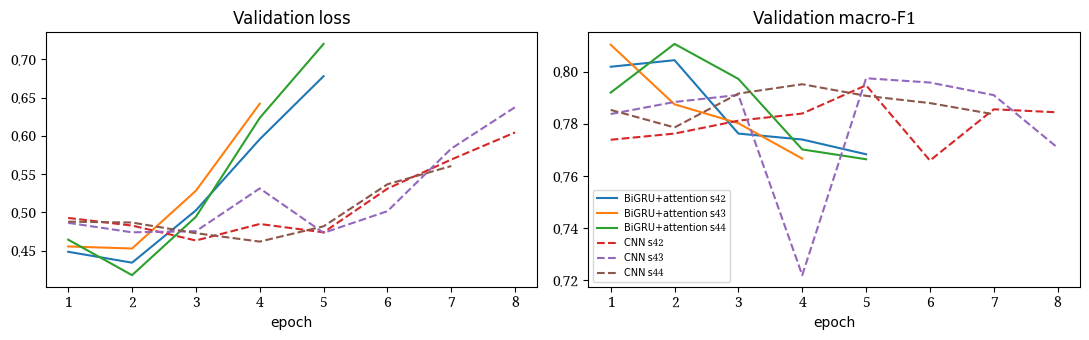

In [42]:
# Validation macro-F1 of the seed-averaged networks and their training curves
val_ids = encode(list(val['text']), neural_vocab)
for name, models in neural.items():
    val_probs[name] = average_probs(models, val_ids)
neural_f1 = {name: macro_f1(y_val, val_probs[name] >= 0.5) for name in neural}
best_neural = max(neural_f1, key=neural_f1.get)
print('validation macro-F1 (3 seeds averaged):', {n: round(f, 4) for n, f in neural_f1.items()}, '| best neural:', best_neural)

hist = neural_history[neural_history['augmentation'] == USE_AUG_NEURAL]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for (name, seed), h in hist.groupby(['model', 'seed']):
    style = '-' if name == 'BiGRU+attention' else '--'
    ax[0].plot(h['epoch'], h['val_loss'], style, label=f'{name} s{seed}')
    ax[1].plot(h['epoch'], h['val_macro_f1'], style, label=f'{name} s{seed}')
ax[0].set_title('Validation loss'); ax[1].set_title('Validation macro-F1')
for a in ax:
    a.set_xlabel('epoch')
ax[1].legend(fontsize=7)
plt.tight_layout(); save_figure(fig, 'neural_training_history.png'); plt.show()

The augmentation table above is read from the saved training log: with augmentation both networks scored higher on validation (BiGRU 0.8049 → 0.8170,
CNN 0.7991 → 0.8085), so the selection rule keeps augmentation. This is a selection decision on one validation set, not a tested finding.
Re-scoring the saved checkpoints in the cell above gives 0.8114 (BiGRU) and 0.8056 (CNN); these re-scored values are the ones used for the ensemble,
the final-model choice and every later table. Validation loss reaches its minimum around epoch 2 for the BiGRU and epochs 3–5 for the CNN and then rises:
the networks start to overfit, and early stopping restores the best epoch.

### 4.3 Transformer

#### Model E: XLM-RoBERTa large (fine-tuned)

`xlm-roberta-large` is pretrained on CommonCrawl text in 100 languages **including Urdu**, so its SentencePiece vocabulary covers Urdu script,
Roman-Urdu/English words and emojis.

*Why: it brings pretrained knowledge of Urdu usage that 11k training posts alone cannot provide.*

It reads the cleaned text, truncated to 128 subwords, without augmentation.

Training: up to 5 epochs, early stopping (patience 2) on validation macro-F1, best checkpoint restored, three seeds averaged.

A run that predicts only one class on validation would be discarded and replaced by a spare seed (none was needed).

In [43]:
# XLM-R helpers: mixed-precision inference and one training epoch
LABEL2ID = {LABEL_NAMES[0]: 0, LABEL_NAMES[1]: 1}
ID2LABEL = {0: LABEL_NAMES[0], 1: LABEL_NAMES[1]}
EVAL_SETS = {'val': val['text'].tolist(), 'test': test['text'].tolist(),
             'drop': typo['text_drop'].tolist(), 'swap': typo['text_swap'].tolist()}

def amp():
    return torch.autocast(device_type=device, dtype=torch.float16, enabled=device == 'cuda')

def xlmr_probs(model, tok, texts, batch: int = 64) -> np.ndarray:
    model.eval()
    out = []
    with torch.no_grad(), amp():
        for i in range(0, len(texts), batch):
            enc = tok(list(texts[i:i + batch]), truncation=True, max_length=XLMR['max_len'],
                      padding=True, return_tensors='pt').to(device)
            out.append(torch.softmax(model(**enc).logits.float(), -1)[:, 1].cpu())
    return torch.cat(out).numpy()

def xlmr_epoch(model, tok, opt, sched, scaler, texts, labels) -> float:
    model.train()
    losses = []
    for idx in np.array_split(np.random.permutation(len(texts)), math.ceil(len(texts) / XLMR['batch'])):
        enc = tok([texts[i] for i in idx], truncation=True, max_length=XLMR['max_len'], padding=True, return_tensors='pt').to(device)
        with amp():
            loss = model(**enc, labels=torch.tensor(labels[idx]).to(device)).loss
        opt.zero_grad()
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt)
        scaler.update()
        sched.step()
        losses.append(loss.item())
    return float(np.mean(losses))

In [44]:
# Fine-tune one seed, and save / load a finished run
def run_dir_for(model_name: str, seed: int, mode: str = 'raw') -> Path:
    return DIRS['transformer'] / (f'{model_name}_seed{seed}' + ('' if mode == 'raw' else f'_{mode}'))

def finetune_xlmr(model_name: str, seed: int, mode: str = 'raw') -> dict:
    set_seed(seed)
    prep = (lambda ts: list(ts)) if mode == 'raw' else (lambda ts: [normalize_urdu(t, mode) for t in ts])   # 'raw' = cleaned text only
    eval_sets = {split: prep(texts_) for split, texts_ in EVAL_SETS.items()}
    tok = AutoTokenizer.from_pretrained(model_name)
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2, id2label=ID2LABEL,
                                                               label2id=LABEL2ID).to(device)
    texts, labels = prep(train['text']), train['label'].values   # original posts, no augmentation
    opt = torch.optim.AdamW(model.parameters(), lr=XLMR['lr'], weight_decay=XLMR['weight_decay'])
    total = XLMR['max_epochs'] * math.ceil(len(texts) / XLMR['batch'])
    sched = get_linear_schedule_with_warmup(opt, int(XLMR['warmup'] * total), total)
    scaler = torch.amp.GradScaler(enabled=device == 'cuda')
    stopper, history = EarlyStopping(XLMR['patience'], half_precision=True), []
    for epoch in range(1, XLMR['max_epochs'] + 1):
        train_loss = xlmr_epoch(model, tok, opt, sched, scaler, texts, labels)
        p = xlmr_probs(model, tok, eval_sets['val'])
        f1 = macro_f1(y_val, p >= 0.5)
        history.append({'epoch': epoch, 'train_loss': train_loss, 'val_loss': log_loss(y_val, p, labels=[0, 1]), 'val_macro_f1': f1})
        print(f'  {model_name} seed {seed} epoch {epoch}: train loss {train_loss:.4f} | validation macro-F1 {f1:.4f}')
        if stopper.step(f1, epoch, model):
            print('  early stopping')
            break
    stopper.restore(model)
    run = {'model': model_name, 'seed': seed, 'mode': mode, 'best_epoch': stopper.best_epoch, 'val_macro_f1': stopper.best_score,
           **{split: xlmr_probs(model, tok, texts_) for split, texts_ in eval_sets.items()}}
    run['collapsed'] = bool(len(np.unique(run['val'] >= 0.5)) < 2)
    save_xlmr_run(run, model, tok, history)
    del model, stopper
    torch.cuda.empty_cache()
    return run

def save_xlmr_run(run: dict, model, tok, history) -> None:
    out = run_dir_for(run['model'], run['seed'], run.get('mode', 'raw'))
    out.mkdir(parents=True, exist_ok=True)
    if not run['collapsed']:
        model.half().save_pretrained(out)   # safetensors, fp16
        tok.save_pretrained(out)
    for split in EVAL_SETS:
        np.save(out / f'probs_{split}.npy', run[split])
    pd.DataFrame(history).to_csv(out / 'history.csv', index=False)
    save_json({k: run[k] for k in ['model', 'seed', 'best_epoch', 'val_macro_f1', 'collapsed']}
              | {'config': XLMR, 'label2id': LABEL2ID, 'mode': run.get('mode', 'raw'),
                 'input': 'clean_unicode(text), no normalize_urdu' if run.get('mode', 'raw') == 'raw' else f"normalize_urdu(text, {run['mode']!r})"},
              out / 'run_info.json')

def load_xlmr_run(model_name: str, seed: int, mode: str = 'raw') -> dict:
    out = run_dir_for(model_name, seed, mode)
    run = json.loads((out / 'run_info.json').read_text(encoding='utf-8'))
    run.update({split: np.load(out / f'probs_{split}.npy') for split in EVAL_SETS})
    for split, texts_ in EVAL_SETS.items():
        assert len(run[split]) == len(texts_), f'{out} was produced for a different split'
    return run

In [45]:
# Run (or load) the seeds and average their probabilities
def run_xlmr_experiment():
    good, log = [], []
    for model_name in XLMR['models']:
        for seed in XLMR['seeds']:
            if len(good) == XLMR['n_good_runs']:
                break
            if RESUME and (run_dir_for(model_name, seed) / 'run_info.json').exists():
                run = load_xlmr_run(model_name, seed)
                print(f'loaded finished run {model_name} seed {seed}: best epoch {run["best_epoch"]}, '
                      f'validation macro-F1 {run["val_macro_f1"]:.4f}')
            elif device == 'cuda':
                run = finetune_xlmr(model_name, seed)
            else:
                print('No GPU and no saved runs: XLM-R is skipped. A GPU is needed to train it.')
                return good, log
            log.append({k: run[k] for k in ['model', 'seed', 'best_epoch', 'val_macro_f1', 'collapsed']})
            if not run['collapsed']:
                good.append(run)
        if good:
            break   # xlm-roberta-base only if every large run collapsed
    return good, log

xlmr_good, xlmr_log = run_xlmr_experiment()
HAS_XLMR = len(xlmr_good) > 0
if HAS_XLMR:
    for split in EVAL_SETS:   # final XLM-R = average of the successful seeds
        np.save(DIRS['results'] / f'xlmr_{split}.npy', np.mean([r[split] for r in xlmr_good], axis=0))
    xlmr_runs = pd.DataFrame(xlmr_log)
    xlmr_runs.to_csv(DIRS['results'] / 'xlmr_runs.csv', index=False)
    val_probs['XLM-R'] = np.load(DIRS['results'] / 'xlmr_val.npy')
    print(xlmr_runs.round(4).to_string(index=False))
    print('XLM-R validation macro-F1 (seeds averaged):', round(macro_f1(y_val, val_probs['XLM-R'] >= 0.5), 4))

loaded finished run xlm-roberta-large seed 42: best epoch 3, validation macro-F1 0.8248
loaded finished run xlm-roberta-large seed 43: best epoch 2, validation macro-F1 0.8233
loaded finished run xlm-roberta-large seed 44: best epoch 4, validation macro-F1 0.8182
            model  seed  best_epoch  val_macro_f1  collapsed
xlm-roberta-large    42           3        0.8248      False
xlm-roberta-large    43           2        0.8233      False
xlm-roberta-large    44           4        0.8182      False
XLM-R validation macro-F1 (seeds averaged): 0.8312


#### RESUME safety check

`load_xlmr_run` refuses saved probabilities whose length does not match the current split. The next cell builds a deliberately wrong run, confirms that the
assertion fires and deletes it again.

In [46]:
# Demonstrate that load_xlmr_run rejects saved probabilities that do not match the current split, then clean up
import shutil
fake_dir = run_dir_for('_resume_check', 0)
fake_dir.mkdir(parents=True, exist_ok=True)
save_json({'model': '_resume_check', 'seed': 0, 'best_epoch': 0, 'val_macro_f1': 0.0, 'collapsed': False}, fake_dir / 'run_info.json')
for split, texts_ in EVAL_SETS.items():
    np.save(fake_dir / f'probs_{split}.npy', np.zeros(len(texts_) - 1))   # deliberately one row short
try:
    load_xlmr_run('_resume_check', 0)
    caught = False
except AssertionError as err:
    caught = True
    print('assertion fired as expected:', err)
finally:
    shutil.rmtree(fake_dir)   # remove the artificial run
assert caught, 'the RESUME length check did not fire'
print('artificial run removed:', not fake_dir.exists())

assertion fired as expected: /content/drive/MyDrive/Urdu_Sarcasm_Detection/transformer/_resume_check_seed0 was produced for a different split
artificial run removed: True


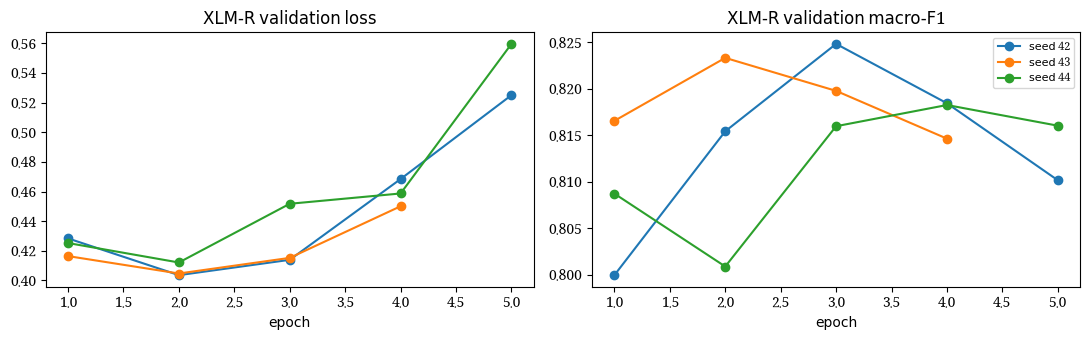

,epoch,train_loss,val_loss,val_macro_f1,model,seed
0,1,0.5226,0.4284,0.8000,xlm-roberta-large,42
1,2,0.4051,0.4036,0.8154,xlm-roberta-large,42
2,3,0.3583,0.4139,0.8248,xlm-roberta-large,42
3,4,0.3073,0.4684,0.8184,xlm-roberta-large,42
4,5,0.2680,0.5250,0.8102,xlm-roberta-large,42
5,1,0.5251,0.4164,0.8165,xlm-roberta-large,43
6,2,0.4066,0.4047,0.8233,xlm-roberta-large,43
7,3,0.3560,0.4152,0.8198,xlm-roberta-large,43
8,4,0.3083,0.4501,0.8146,xlm-roberta-large,43
9,1,0.5342,0.4252,0.8087,xlm-roberta-large,44


In [47]:
# per-epoch training history of every saved XLM-R run
histories = []
for r in xlmr_log:
    path = run_dir_for(r['model'], r['seed']) / 'history.csv'
    if path.exists():
        histories.append(pd.read_csv(path).assign(model=r['model'], seed=r['seed']))
if histories:
    xlmr_history = pd.concat(histories, ignore_index=True)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    for (name, seed), h in xlmr_history.groupby(['model', 'seed']):
        ax[0].plot(h['epoch'], h['val_loss'], marker='o', label=f'seed {seed}')
        ax[1].plot(h['epoch'], h['val_macro_f1'], marker='o', label=f'seed {seed}')
    ax[0].set_title('XLM-R validation loss'); ax[1].set_title('XLM-R validation macro-F1')
    for a in ax:
        a.set_xlabel('epoch')
    ax[1].legend(fontsize=8)
    plt.tight_layout(); save_figure(fig, 'xlmr_training_history.png'); plt.show()
    display(xlmr_history.round(4))

### 4.4 Ensemble and final-model selection

The ensemble averages the probabilities of the best model of each family (Logistic Regression, BiGRU, XLM-R; LogReg and LinearSVC tie at 0.8083 on validation and LogReg, listed first, is kept) with weights on a 0.1 grid and a threshold in
0.30–0.70, both chosen on validation. *Why: the three families make different errors, so combining them can help.*
The **final model is the one with the highest validation macro-F1**, fixed here before the test set is read. **The ensemble's validation score (0.8404) is optimistic** because its weights and threshold were tuned on the same validation set; its **test score (0.8329) is the honest estimate**. The nested check after the next cell quantifies the optimism: weights and threshold are tuned on 30% of validation and every model is scored on the untouched 70%.

In [48]:
# Grid-search ensemble weights and threshold on validation, then pick the final model
members = [best_classical, best_neural] + (['XLM-R'] if HAS_XLMR else [])
weight_grid = [w for w in itertools.product(np.arange(0, 1.01, 0.1), repeat=len(members)) if abs(sum(w) - 1) < 1e-9]
best_ens = (-1, None, None)
for w in weight_grid:
    mixed = sum(wi * val_probs[m] for wi, m in zip(w, members))
    for threshold in np.arange(0.30, 0.701, 0.01):
        f1 = macro_f1(y_val, mixed >= threshold)
        if f1 > best_ens[0]:
            best_ens = (f1, w, threshold)
ENS_WEIGHTS = {m: round(float(w), 1) for m, w in zip(members, best_ens[1])}
ENS_THR = round(float(best_ens[2]), 2)
val_probs['Ensemble'] = sum(w * val_probs[m] for m, w in ENS_WEIGHTS.items())
THRESH = {m: 0.5 for m in val_probs}
THRESH['Ensemble'] = ENS_THR

val_summary = pd.DataFrame({'val_macro_f1': {m: macro_f1(y_val, val_probs[m] >= THRESH[m]) for m in val_probs},
                            'threshold': THRESH}).sort_values('val_macro_f1', ascending=False).round(4)
FINAL_MODEL = val_summary.index[0]
BEST_SINGLE = val_summary.drop(index='Ensemble').index[0]
save_json({'members': members, 'weights': ENS_WEIGHTS, 'threshold': ENS_THR, 'final_model': FINAL_MODEL,
           'best_single_model': BEST_SINGLE}, DIRS['config'] / 'ensemble_and_selection.json')
val_summary.to_csv(DIRS['results'] / 'validation_summary.csv')
print('ensemble weights:', ENS_WEIGHTS, '| threshold:', ENS_THR)
print('FINAL MODEL (chosen on validation):', FINAL_MODEL, '| best single model:', BEST_SINGLE)
val_summary

ensemble weights: {'LogReg': 0.3, 'BiGRU+attention': 0.2, 'XLM-R': 0.5} | threshold: 0.46
FINAL MODEL (chosen on validation): Ensemble | best single model: XLM-R


,val_macro_f1,threshold
Ensemble,0.8404,0.46
XLM-R,0.8312,0.50
BiGRU+attention,0.8114,0.50
LogReg,0.8083,0.50
LinearSVC,0.8083,0.50
CNN,0.8056,0.50


In [49]:
# Nested check: tune ensemble weights/threshold on 30% of validation, evaluate everything on the untouched 70%
tune_idx, hold_idx = train_test_split(np.arange(len(y_val)), test_size=0.7, stratify=y_val, random_state=SEED)

def tune_ensemble(idx):
    best = (-1, None, None)
    for w in weight_grid:
        mixed = sum(wi * val_probs[m][idx] for wi, m in zip(w, members))
        for threshold in np.arange(0.30, 0.701, 0.01):
            f1 = macro_f1(y_val[idx], mixed >= threshold)
            if f1 > best[0]:
                best = (f1, w, threshold)
    return best

_, w_nested, thr_nested = tune_ensemble(tune_idx)
y_hold = y_val[hold_idx]
nested_pred = (sum(wi * val_probs[m][hold_idx] for wi, m in zip(w_nested, members)) >= thr_nested).astype(int)
rows_nested = [{'model': f'Ensemble (tuned on 30%: weights {dict(zip(members, np.round(w_nested, 1)))}, threshold {thr_nested:.2f})',
                'hold-out macro-F1': macro_f1(y_hold, nested_pred)},
               {'model': 'Ensemble (tuned on all validation, optimistic reference)',
                'hold-out macro-F1': macro_f1(y_hold, val_probs['Ensemble'][hold_idx] >= ENS_THR)}]
rows_nested += [{'model': m, 'hold-out macro-F1': macro_f1(y_hold, val_probs[m][hold_idx] >= 0.5)} for m in members]
display(pd.DataFrame(rows_nested).round(4))
only_e, only_x, p = mcnemar_p(y_hold, nested_pred, (val_probs['XLM-R'][hold_idx] >= 0.5).astype(int))
print(f'{len(hold_idx)} hold-out posts | McNemar nested Ensemble vs XLM-R: only Ensemble right = {only_e}, only XLM-R right = {only_x}, p = {p:.4g}')

,model,hold-out macro-F1
0,"Ensemble (tuned on 30%: weights {'LogReg': np.float64(0.5), 'BiGRU+attention': np.float64(0.3), 'XLM-R': n...",0.8186
1,"Ensemble (tuned on all validation, optimistic reference)",0.8338
2,LogReg,0.7983
3,BiGRU+attention,0.8067
4,XLM-R,0.8268


1020 hold-out posts | McNemar nested Ensemble vs XLM-R: only Ensemble right = 38, only XLM-R right = 44, p = 0.5811


## 5. Ablation Study (validation only)

Each row changes **one** choice of the TF-IDF + Logistic Regression setup (Model A: same features, C and class weight) and reports validation macro-F1 and an exact McNemar p-value against the base setup. Removals are applied to both training and validation text.

Code-mixing is split into **Roman-Urdu tokens** (a seed list of common Roman-Urdu words such as *hai, kya, nahi, bilkul*) and **other Latin-script tokens** (mostly English, plus Roman-Urdu words outside the seed list, names and acronyms). Words that are also common English words (*to, the, me, main, is, in, par*) are left out of the seed list to avoid mislabelling English.

In [50]:
# One-change-at-a-time ablation of preprocessing and feature choices, with an exact McNemar test against the base setup
HASHTAG = re.compile(r'#\S+')
LATIN_WORD = re.compile(r"(?<![#@\w])[A-Za-z][A-Za-z0-9_']*")   # Latin-script words; hashtags and mentions kept
LONG_RUN = re.compile(r'(.)\1{2,}')                               # any character repeated 3+ times
ROMAN_URDU = set("""hai hain hoga hogi honge tha thi thay kya kia kyun kyon kyu kaise kaisa kaisi kab kahan kon kaun nahi nahin nai nhi
aur bhi sirf sab kuch koi bohat bahut bht acha achha accha theek thik ji jee haan yaar yar bhai wah waah bilkul shabash kamal zabardast
yeh ye woh wo wahi yahi mera meri mere tera teri tere apna apni apne hum tum aap unka unki iska iski uska uski kar karo karna karte karta
karti kiya kiye raha rahi rahe gaya gayi gaye hua hui diya liya dekho suno chalo lagta lagti abhi phir pehle baad sath saath liye wala wali
wale ka ki ke ko se mein mai inshallah mashallah""".split())   # common Roman-Urdu words; words that are also English are left out

def edit_text(d: pd.DataFrame, fn) -> pd.DataFrame:
    return d.assign(text=d['text'].map(lambda t: re.sub(r'\s+', ' ', fn(t)).strip()))

def strip_pattern(d: pd.DataFrame, pattern: re.Pattern) -> pd.DataFrame:
    return edit_text(d, lambda t: pattern.sub(' ', t))

def per_word(fn):   # apply fn to every word except URLs
    return lambda t: ' '.join(w if URL_RE.match(w) else fn(w) for w in t.split())

def drop_latin(which: str):   # 'all', 'roman' (seed list) or 'other' Latin-script tokens
    keep = lambda tok: (which == 'roman' and tok.lower() not in ROMAN_URDU) or (which == 'other' and tok.lower() in ROMAN_URDU)
    return per_word(lambda w: LATIN_WORD.sub(lambda m: m.group() if keep(m.group()) else ' ', w))

no_punct = per_word(lambda w: ''.join(' ' if unicodedata.category(c).startswith('P') and c not in '#@_' else c for c in w))
no_repeat = per_word(lambda w: LONG_RUN.sub(r'\1', w))

latin_tokens = [m.group().lower() for t in fit_train['text'] for w in t.split() if not URL_RE.match(w) for m in LATIN_WORD.finditer(w)]
n_roman = sum(tok in ROMAN_URDU for tok in latin_tokens)
print(f'Latin-script tokens in training posts: {len(latin_tokens)} | Roman-Urdu (seed list): {n_roman} | other: {len(latin_tokens) - n_roman}')

def val_predict(train_df, val_df, model, **options) -> np.ndarray:
    feats_ = fit_features(train_df, **options)
    model.fit(transform(feats_, train_df['text']), train_df['label'])
    return model.predict(transform(feats_, val_df['text']))

other_train = train if USE_AUG else train_plus
variants = [('base (final setup)', 'base', fit_train, val, {})]
variants += [(f'preprocessing: {m}', 'preprocessing', fit_train, val, {'mode': m}) for m in MODES if m != MODE]
variants += [('emojis removed', 'emojis', strip_pattern(fit_train, EMOJI), strip_pattern(val, EMOJI), {}),
             ('hashtags removed', 'hashtags', strip_pattern(fit_train, HASHTAG), strip_pattern(val, HASHTAG), {}),
             ('punctuation removed', 'punctuation', edit_text(fit_train, no_punct), edit_text(val, no_punct), {}),
             ('repetition collapsed (3+ runs -> 1)', 'repetition', edit_text(fit_train, no_repeat), edit_text(val, no_repeat), {}),
             ('Latin-script tokens removed (all)', 'code-mixing', edit_text(fit_train, drop_latin('all')), edit_text(val, drop_latin('all')), {}),
             ('Roman-Urdu tokens removed (seed list)', 'code-mixing', edit_text(fit_train, drop_latin('roman')), edit_text(val, drop_latin('roman')), {}),
             ('other Latin tokens removed (mostly English)', 'code-mixing', edit_text(fit_train, drop_latin('other')), edit_text(val, drop_latin('other')), {}),
             ('word n-grams only', 'features', fit_train, val, {'char': False}),
             ('char n-grams only', 'features', fit_train, val, {'word': False}),
             ('no phrase or cue features', 'engineered', fit_train, val, {'phrases': False, 'cues': False}),
             ('+ Urdu marker lexicon', 'engineered', fit_train, val, {'lexicon': True}),
             (f'augmentation = {not USE_AUG}', 'augmentation', other_train, val, {})]
ablation, base_pred = [], None
for name, group, train_df, val_df, options in variants:
    pred = val_predict(train_df, val_df, make_lr(lr_C, lr_weight), **{'mode': MODE, **options})
    base_pred = pred if base_pred is None else base_pred
    ablation.append({'group': group, 'variant': name, 'val_macro_f1': round(macro_f1(y_val, pred), 4),
                     'mcnemar_p_vs_base': round(mcnemar_p(y_val, base_pred, pred)[2], 4)})
ablation = pd.DataFrame(ablation)
ablation['delta_vs_base'] = (ablation['val_macro_f1'] - ablation['val_macro_f1'].iloc[0]).round(4)
ablation.to_csv(DIRS['results'] / 'ablation_validation.csv', index=False)
print('variants with p < 0.05:', int((ablation['mcnemar_p_vs_base'].iloc[1:] < 0.05).sum()), 'of', len(ablation) - 1)
ablation[['group', 'variant', 'val_macro_f1', 'delta_vs_base', 'mcnemar_p_vs_base']]

Latin-script tokens in training posts: 1403 | Roman-Urdu (seed list): 13 | other: 1390
variants with p < 0.05: 0 of 14


,group,variant,val_macro_f1,delta_vs_base,mcnemar_p_vs_base
0,base,base (final setup),0.8083,0.0000,1.0000
1,preprocessing,preprocessing: raw,0.8100,0.0017,0.7905
2,preprocessing,preprocessing: light,0.8084,0.0001,1.0000
3,emojis,emojis removed,0.8028,-0.0055,0.3817
4,hashtags,hashtags removed,0.8038,-0.0045,0.2559
5,punctuation,punctuation removed,0.8127,0.0044,0.2863
6,repetition,repetition collapsed (3+ runs -> 1),0.8095,0.0012,0.8318
7,code-mixing,Latin-script tokens removed (all),0.8097,0.0014,0.6875
8,code-mixing,Roman-Urdu tokens removed (seed list),0.8091,0.0008,1.0000
9,code-mixing,other Latin tokens removed (mostly English),0.8097,0.0014,0.6875


**Findings.** No variant differs significantly from the base (all 14 McNemar p ≥ 0.25), and every delta is below 0.006, inside the ±0.02 validation noise.

* **Emojis** (−0.0055, p = 0.38) and **hashtags** (−0.0045, p = 0.26): removing them lowers the score slightly but not significantly. The ablation does **not** show that emojis or hashtags are useful cues.
* **Punctuation** (+0.0044, p = 0.29), **repetition** (+0.0012, p = 0.83) and **all Latin-script tokens** (+0.0014, p = 0.69): removing them raises the score slightly, again not significantly.
* **Code-mixing:** only 13 of the 1,403 Latin-script tokens in the training posts are in the Roman-Urdu seed list; the rest are mostly English words, names and acronyms.
  Removing the seed-list Roman-Urdu tokens changes the score by +0.0008 (p = 1.0); removing the other Latin tokens gives the same result as removing all of them (+0.0014, p = 0.69).
  In this corpus the Latin-script ablation is therefore effectively an English-token ablation. The seed list is small and misses rarer Roman-Urdu spellings.
* **Normalisation:** `raw` +0.0017 (p = 0.79) and `light` +0.0001 (p = 1.0) versus `full`.
* **Word vs character n-grams:** word-only −0.0011 (p = 0.92), char-only −0.0044 (p = 0.41).
* **Engineered features:** removing phrases and cues +0.0015 (p = 1.0); adding the lexicon +0.0022 (p = 0.61). **Augmentation** for the linear model: +0.0007 (p = 1.0).

Because nothing is significant, the cue-preserving pipeline is kept as designed.

### 5.1 Cue-by-cue ablation

Each of the 11 cue features is removed in turn from the final Model A features; the delta and a McNemar p-value against the base are reported.

In [51]:
# Remove one cue column at a time from the final Model A features (MaxAbs scaling is per column, so this equals refitting without it)
base_val_pred = lr_model.predict(X_val)
n_cols = X_train.shape[1]
cue_rows = []
for k, cue in enumerate(CUE_NAMES):
    keep = np.r_[0:n_cols - len(CUE_NAMES) + k, n_cols - len(CUE_NAMES) + k + 1:n_cols]   # drop one cue column
    pred = make_lr(lr_C, lr_weight).fit(X_train[:, keep], y_train).predict(X_val[:, keep])
    only_base, only_var, p = mcnemar_p(y_val, base_val_pred, pred)
    cue_rows.append({'cue removed': cue, 'val_macro_f1': macro_f1(y_val, pred),
                     'delta_vs_base': macro_f1(y_val, pred) - macro_f1(y_val, base_val_pred), 'mcnemar_p': p})
cue_ablation = pd.DataFrame(cue_rows).round(4)
cue_ablation.to_csv(DIRS['results'] / 'ablation_cue_by_cue.csv', index=False)
print('base (all 11 cues):', round(macro_f1(y_val, base_val_pred), 4), '| significant at 0.05:', int((cue_ablation['mcnemar_p'] < 0.05).sum()), 'of', len(cue_ablation))
cue_ablation

base (all 11 cues): 0.8083 | significant at 0.05: 0 of 11


,cue removed,val_macro_f1,delta_vs_base,mcnemar_p
0,emoji,0.8078,-0.0006,1.0000
1,exclaim,0.8083,0.0000,1.0000
2,question,0.8083,0.0000,1.0000
3,ellipsis,0.8075,-0.0008,1.0000
4,char_runs,0.8083,0.0000,1.0000
5,latin_ratio,0.8083,0.0000,1.0000
6,quoted_words,0.8083,0.0000,1.0000
7,url,0.8084,0.0001,1.0000
8,mention,0.8101,0.0018,0.7539
9,hashtag,0.8088,0.0005,1.0000


No single cue changes validation macro-F1 significantly (all p ≥ 0.39).
- Five cues (`exclaim`, `question`, `char_runs`, `latin_ratio`, `quoted_words`) leave macro-F1 unchanged to four decimals.
- Removing `log_words` (post length) has the largest effect (−0.0040, p = 0.39), then `ellipsis` (−0.0008) and `emoji` (−0.0006).
- Removing `url`, `hashtag` or `mention` raises the score slightly (+0.0001 to +0.0018).
- No individual cue is shown to help or to hurt.

### 5.2 Phrase-mining sweep

The phrase miner's `min_count` (3, 5, 10) and log-odds smoothing constant (0.1, 0.5, 1.0) are varied with everything else fixed, to check whether the small
effect of the phrase features is caused by a poor choice of these settings.

In [52]:
# Phrase-mining sweep: min_count x log-odds smoothing, all other Model A features and settings fixed
norm_train = np.array([normalize_urdu(t, MODE) for t in fit_train['text']])
norm_val = [normalize_urdu(t, MODE) for t in val['text']]
n_tfidf = sum(len(block.vocabulary_) for block in feats['tfidf'])
tfidf_tr, tfidf_va = X_train[:, :n_tfidf], X_val[:, :n_tfidf]
cue_tr, cue_va = X_train[:, -len(CUE_NAMES):], X_val[:, -len(CUE_NAMES):]
sweep_rows = []
for min_count, alpha in itertools.product([3, 5, 10], [0.1, 0.5, 1.0]):
    sarcastic, plain = mine_phrases(norm_train, fit_train['label'].values, min_count=min_count, alpha=alpha)
    cv = CountVectorizer(vocabulary=list(dict.fromkeys(sarcastic + plain)), ngram_range=(2, 3), token_pattern=WORD_PATTERN, binary=True)
    Xtr = sp.hstack([tfidf_tr, cv.transform(norm_train), cue_tr]).tocsr()
    Xva = sp.hstack([tfidf_va, cv.transform(norm_val), cue_va]).tocsr()
    pred = make_lr(lr_C, lr_weight).fit(Xtr, y_train).predict(Xva)
    sweep_rows.append({'min_count': min_count, 'smoothing': alpha, 'val_macro_f1': macro_f1(y_val, pred),
                       'mcnemar_p_vs_final': mcnemar_p(y_val, base_val_pred, pred)[2]})
phrase_sweep = pd.DataFrame(sweep_rows).round(4)
phrase_sweep.to_csv(DIRS['results'] / 'phrase_mining_sweep.csv', index=False)
print('final setting: min_count = 5, smoothing = 0.5 | range of validation macro-F1:',
      phrase_sweep['val_macro_f1'].min(), '-', phrase_sweep['val_macro_f1'].max(), '| smallest McNemar p:', phrase_sweep['mcnemar_p_vs_final'].min())
phrase_sweep.pivot(index='min_count', columns='smoothing', values='val_macro_f1')

final setting: min_count = 5, smoothing = 0.5 | range of validation macro-F1: 0.8074 - 0.8103 | smallest McNemar p: 0.25


smoothing,0.1,0.5,1.0
min_count,,,
3,0.8082,0.8091,0.8103
5,0.8074,0.8083,0.8103
10,0.8087,0.8089,0.8089


Across the nine settings validation macro-F1 ranges from 0.8074 to 0.8103 (final setting 0.8083), and no setting differs significantly from the final one
(smallest McNemar p = 0.25). The small effect of the phrase features is therefore not caused by a poor choice of `min_count` or smoothing.

### 5.3 Summary: the ablation is a null result

**No single preprocessing or feature choice has been shown to matter for the TF-IDF model.**
- The 14 variants, the 11 single-cue removals and the 9 phrase-mining settings all leave the score within 0.006 macro-F1 of the base.
- None is significant: every McNemar p is at least 0.25.
- The largest contribution comes from the **model family**, not from any preprocessing choice. On test the models range from 0.7594 (B2) to 0.8365 (XLM-R) macro-F1; which of these differences are significant is tested in Section 6.5.
- The preprocessing and feature choices in Sections 2–3 are therefore justified by linguistic reasoning and leakage control, not by measured gains.

## 6. Evaluation

Every model is reported with accuracy, precision, recall and F1 for each class, macro-F1 (primary metric) and a confusion matrix.

### 6.1 Sanity checks

* the normaliser is idempotent;
* majority-class and shuffled-label baselines show what "no learning" scores (a shuffled-label model near 0.5 macro-F1 also rules out leakage through the features);
* XLM-R tokenizer coverage (`<unk>` rate) per preprocessing mode.

In [53]:
# Idempotence, majority-class baseline and shuffled-label leakage check
for m in MODES:
    assert all(normalize_urdu(normalize_urdu(t, m), m) == normalize_urdu(t, m) for t in train['text']), m
print('normaliser idempotent on', len(train), 'training posts for modes', MODES)

majority = np.zeros_like(y_val)   # always predict non-sarcastic
print(f'majority-class baseline: validation macro-F1 {macro_f1(y_val, majority):.3f}, accuracy {accuracy_score(y_val, majority):.3f}')

shuffled = np.random.default_rng(SEED).permutation(y_train)
pred = make_lr(lr_C, lr_weight).fit(X_train, shuffled).predict(X_val)
print(f'shuffled labels: validation macro-F1 {macro_f1(y_val, pred):.3f}, accuracy {accuracy_score(y_val, pred):.3f}')
assert macro_f1(y_val, pred) < 0.56, 'a model trained on shuffled labels should not beat chance: check for leakage'

normaliser idempotent on 11201 training posts for modes ['raw', 'light', 'full']
majority-class baseline: validation macro-F1 0.373, accuracy 0.594
shuffled labels: validation macro-F1 0.503, accuracy 0.519


In [54]:
# XLM-R tokens per word and <unk> rate per preprocessing mode
try:
    xlmr_tok = AutoTokenizer.from_pretrained('xlm-roberta-large')
except Exception as err:   # needs Hugging Face Hub access
    xlmr_tok = None
    print('XLM-R tokenizer not available, check skipped:', type(err).__name__)

if xlmr_tok is not None:
    rows = []
    for m in MODES:
        texts_m = [normalize_urdu(t, m) for t in train['text']]
        ids = [i for t in texts_m for i in xlmr_tok(t, add_special_tokens=False)['input_ids']]
        rows.append({'mode': m, 'tokens_per_word': len(ids) / sum(len(t.split()) for t in texts_m),
                     'unk_rate': ids.count(xlmr_tok.unk_token_id) / len(ids)})
    bpe = pd.DataFrame(rows).set_index('mode')
    counts = pd.Series(list(''.join(train['text']))).value_counts()
    unknown = [c for c in counts.index[:3000] if xlmr_tok.unk_token_id in xlmr_tok(c, add_special_tokens=False)['input_ids']]
    print(bpe.round(5))
    print('\nmost frequent characters mapped to <unk>:')
    display(pd.DataFrame({'char': unknown[:12], 'code': [f'U+{ord(c):04X}' for c in unknown[:12]], 'count': counts[unknown[:12]].values}))

config.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

       tokens_per_word  unk_rate
mode                            
raw            1.55471   0.00202
light          1.52165   0.00206
full           1.46156   0.00214

most frequent characters mapped to <unk>:


,char,code,count
0,ۿ,U+06FF,134
1,᷂,U+1DC2,74
2,🔄,U+1F504,46
3,🐕,U+1F415,40
4,🌚,U+1F31A,35
5,🙉,U+1F649,27
6,🐅,U+1F405,24
7,🤐,U+1F910,20
8,🥺,U+1F97A,17
9,🇾,U+1F1FE,16


The `<unk>` rate is about 0.2% in every mode: the unknown characters are rare symbols and emojis missing from the vocabulary, not a preprocessing problem.

### 6.2 Held-out test results (all models)

**From here on the test set is read.** All settings, weights, thresholds and the final-model choice were fixed above.
Test predictions are computed once per model and reused below. The table is ordered by validation macro-F1 and includes a 95% bootstrap interval for test macro-F1.

In [55]:
# Test (and typo-variant) probabilities for every model, saved once
y_test = test['label'].values

def all_probs(texts, xlmr_split: str) -> dict:
    texts = list(texts)
    ids = encode(texts, neural_vocab)
    X = transform(feats, texts)
    probs = {name: model.predict_proba(X)[:, 1] for name, model in classical.items()}
    probs.update({name: average_probs(models, ids) for name, models in neural.items()})
    if HAS_XLMR:
        probs['XLM-R'] = np.load(DIRS['results'] / f'xlmr_{xlmr_split}.npy')
        assert len(probs['XLM-R']) == len(texts), f'xlmr_{xlmr_split}.npy does not belong to this split'
    probs['Ensemble'] = sum(w * probs[m] for m, w in ENS_WEIGHTS.items())
    return probs

test_probs = all_probs(test['text'], 'test')
drop_probs = all_probs(typo['text_drop'], 'drop')
swap_probs = all_probs(typo['text_swap'], 'swap')
test_pred = {m: (p >= THRESH[m]).astype(int) for m, p in test_probs.items()}

pred_df = test[['id', 'original_text', 'text', 'label']].copy()
for m in test_probs:
    pred_df[f'prob_{m}'] = test_probs[m].round(4)
    pred_df[f'pred_{m}'] = test_pred[m]
pred_df.to_csv(DIRS['results'] / 'test_predictions.csv', index=False)
val_pred_df = val[['id', 'text', 'label']].assign(**{f'prob_{m}': p.round(4) for m, p in val_probs.items()})
val_pred_df.to_csv(DIRS['results'] / 'val_predictions.csv', index=False)
print('saved test and validation predictions for', list(test_probs))

saved test and validation predictions for ['LogReg', 'LinearSVC', 'BiGRU+attention', 'CNN', 'XLM-R', 'Ensemble']


In [56]:
# Per-class precision/recall/F1, accuracy, macro-F1 and bootstrap interval for every model
def scores(y, pred) -> dict:
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=[0, 1], zero_division=0)
    return {'accuracy': accuracy_score(y, pred), 'precision_0': p[0], 'recall_0': r[0], 'f1_0': f[0],
            'precision_1': p[1], 'recall_1': r[1], 'f1_1': f[1], 'macro_f1': f.mean()}

def bootstrap_ci(y, pred, n: int = 1000):
    rng_ = np.random.default_rng(SEED)
    stats_ = [macro_f1(y[idx], pred[idx]) for idx in (rng_.integers(0, len(y), len(y)) for _ in range(n))]
    return np.percentile(stats_, [2.5, 97.5])

rows = []
for m, pred in test_pred.items():
    low, high = bootstrap_ci(y_test, pred)
    rows.append({'model': m, 'val_macro_f1': macro_f1(y_val, val_probs[m] >= THRESH[m]),
                 **scores(y_test, pred), 'test_f1_ci_low': low, 'test_f1_ci_high': high})
metrics = pd.DataFrame(rows).rename(columns={'macro_f1': 'test_macro_f1'})
metrics = metrics.sort_values('val_macro_f1', ascending=False).round(4).reset_index(drop=True)   # ordered by validation, not test
metrics.to_csv(DIRS['results'] / 'test_metrics.csv', index=False)
print('final model (chosen on validation):', FINAL_MODEL)
metrics

final model (chosen on validation): Ensemble


,model,val_macro_f1,accuracy,precision_0,recall_0,f1_0,precision_1,recall_1,f1_1,test_macro_f1,test_f1_ci_low,test_f1_ci_high
0,Ensemble,0.8404,0.8373,0.8794,0.8418,0.8602,0.7818,0.8308,0.8056,0.8329,0.8136,0.8527
1,XLM-R,0.8312,0.8415,0.8757,0.8545,0.8650,0.7941,0.8223,0.8080,0.8365,0.8165,0.8554
2,BiGRU+attention,0.8114,0.8126,0.8534,0.8268,0.8399,0.7573,0.7919,0.7742,0.8070,0.7865,0.8283
3,LogReg,0.8083,0.8161,0.8421,0.8499,0.8460,0.7770,0.7665,0.7717,0.8088,0.7886,0.8304
4,LinearSVC,0.8083,0.8126,0.8192,0.8788,0.8479,0.8011,0.7157,0.7560,0.8020,0.7803,0.8244
5,CNN,0.8056,0.8071,0.8176,0.8695,0.8428,0.7892,0.7157,0.7507,0.7967,0.7733,0.8181


**Comparison (test macro-F1):** XLM-R 0.8365, Ensemble 0.8329, LogReg 0.8088, BiGRU 0.8070, LinearSVC 0.8020, CNN 0.7967. These are point estimates; which
differences are statistically significant is decided by the pairwise McNemar tests in Section 6.5, not by the ranking.

In [57]:
# Model B2 on the test set (reported for comparison only, never a candidate for the final model)
b2_test_pred = b2_model.predict(b2_scaler.transform(b2_matrix(list(test['text']))))
low, high = bootstrap_ci(test['label'].values, b2_test_pred)
pd.DataFrame([{'model': 'B2 FastText-mean + LogReg', 'val_macro_f1': b2_val_f1, **scores(test['label'].values, b2_test_pred),
               'test_f1_ci_low': low, 'test_f1_ci_high': high}]).rename(columns={'macro_f1': 'test_macro_f1'}).round(4)

,model,val_macro_f1,accuracy,precision_0,recall_0,f1_0,precision_1,recall_1,f1_1,test_macro_f1,test_f1_ci_low,test_f1_ci_high
0,B2 FastText-mean + LogReg,0.768,0.7694,0.7984,0.8187,0.8084,0.7241,0.6971,0.7103,0.7594,0.7361,0.7801


B2 reaches test macro-F1 **0.7594** (95% CI 0.7361–0.7801, accuracy 0.7694), the lowest of all models. B2 is reported for comparison only and is never
a candidate for the final model; its pairwise McNemar tests are in Section 6.5.

### 6.3 Confusion matrices

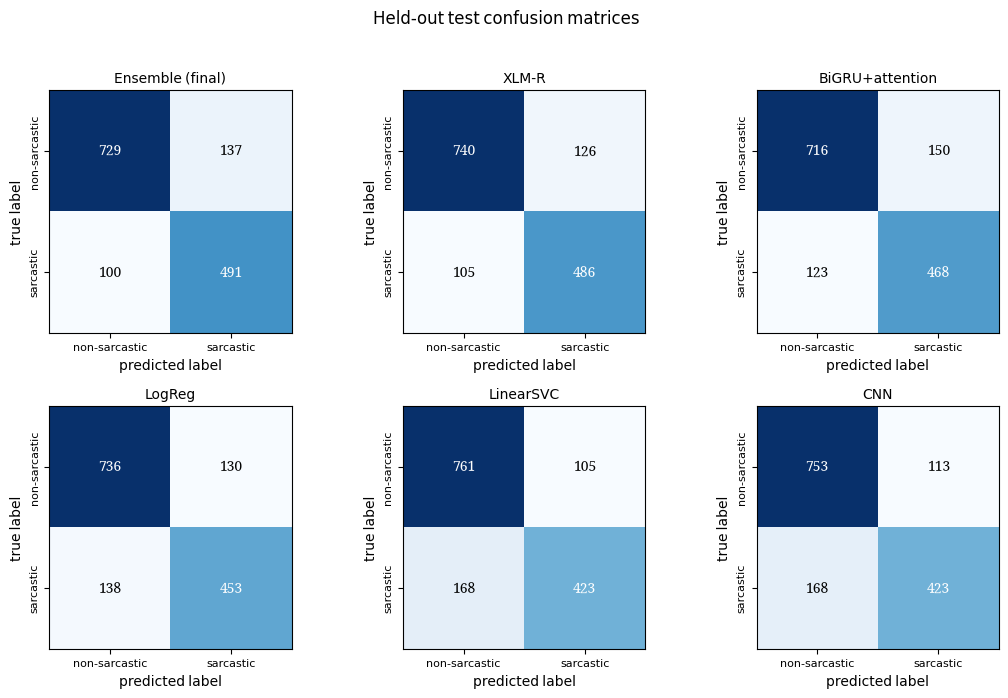

In [58]:
# Test confusion matrix of every model
names = [LABEL_NAMES[0], LABEL_NAMES[1]]
n_cols = 3
n_rows = math.ceil(len(metrics) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.6 * n_cols, 3.4 * n_rows))
axes = np.atleast_1d(axes).ravel()
for ax in axes[len(metrics):]:
    ax.axis('off')
cms = {}
for ax, m in zip(axes, metrics['model']):
    cm = confusion_matrix(y_test, test_pred[m], labels=[0, 1])
    cms[m] = cm.tolist()
    ax.imshow(cm, cmap='Blues')
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha='center', va='center', color='white' if v > cm.max() / 2 else 'black')
    ax.set_xticks([0, 1], names, fontsize=8); ax.set_yticks([0, 1], names, fontsize=8, rotation=90, va='center')
    ax.set_xlabel('predicted label'); ax.set_ylabel('true label')
    ax.set_title(m + (' (final)' if m == FINAL_MODEL else ''), fontsize=10)
fig.suptitle('Held-out test confusion matrices', y=1.02)
fig.tight_layout(); save_figure(fig, 'confusion_matrices_test.png'); plt.show()
save_json(cms, DIRS['results'] / 'confusion_matrices_test.json')

### 6.4 Final model

**The "final model" is a validation-only decision.** The Ensemble was chosen because it had the highest *validation* macro-F1, and that score is optimistic
because the ensemble was tuned on the same set (Section 4.4). The choice does not necessarily generalise: on test, XLM-R alone scores higher (0.8365 vs 0.8329),
and the exact McNemar test between the two gives p = 0.43 (only XLM-R right 23, only Ensemble right 17; Section 6.5), i.e. no significant difference. The Ensemble is reported as the pre-registered
final model, not as the best model.

In [59]:
# Final model in detail
tn, fp, fn, tp = confusion_matrix(y_test, test_pred[FINAL_MODEL], labels=[0, 1]).ravel()
final = metrics.set_index('model').loc[FINAL_MODEL]
print(f'FINAL MODEL: {FINAL_MODEL} (held-out test, {len(y_test)} posts)')
print(f'  sarcastic posts correctly detected (TP):         {tp} of {tp + fn}')
print(f'  sarcastic posts missed (FN):                      {fn}')
print(f'  non-sarcastic posts flagged as sarcastic (FP):    {fp} of {tn + fp}')
print(f'  non-sarcastic posts correctly rejected (TN):      {tn}')
print(f"  sarcasm precision {final['precision_1']:.4f} | sarcasm recall {final['recall_1']:.4f} | sarcasm F1 {final['f1_1']:.4f}")
print(f"  macro-F1 {final['test_macro_f1']:.4f} (95% CI {final['test_f1_ci_low']:.4f}-{final['test_f1_ci_high']:.4f}) | accuracy {final['accuracy']:.4f}")
print(f"  validation macro-F1 {final['val_macro_f1']:.4f} -> test macro-F1 gap {final['test_macro_f1'] - final['val_macro_f1']:+.4f}")

FINAL MODEL: Ensemble (held-out test, 1457 posts)
  sarcastic posts correctly detected (TP):         491 of 591
  sarcastic posts missed (FN):                      100
  non-sarcastic posts flagged as sarcastic (FP):    137 of 866
  non-sarcastic posts correctly rejected (TN):      729
  sarcasm precision 0.7818 | sarcasm recall 0.8308 | sarcasm F1 0.8056
  macro-F1 0.8329 (95% CI 0.8136-0.8527) | accuracy 0.8373
  validation macro-F1 0.8404 -> test macro-F1 gap -0.0075


#### Probability calibration

Section 7.1 ranks errors by model confidence, so the probabilities must be meaningful. The reliability diagram compares predicted probability with the observed
share of sarcastic posts per probability bin; the Brier score and ECE summarise the gap (0 is perfect).

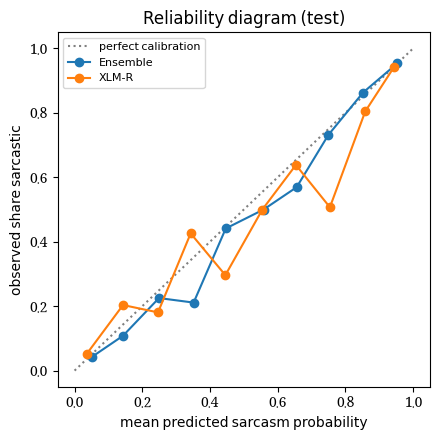

reference Brier of always predicting the base rate 0.406: 0.2411 (lower is better)


,model,brier,ece
0,Ensemble,0.1174,0.0267
1,XLM-R,0.1177,0.0441


In [60]:
# Reliability diagram, Brier score and expected calibration error (ECE) on the test set
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

def ece_score(y, p, n_bins: int = 10) -> float:
    bins = np.minimum((p * n_bins).astype(int), n_bins - 1)   # 10 equal-width probability bins
    return float(sum(abs(y[bins == b].mean() - p[bins == b].mean()) * (bins == b).mean() for b in range(n_bins) if (bins == b).any()))

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], ':', color='grey', label='perfect calibration')
calib_rows = []
for m in dict.fromkeys([FINAL_MODEL, BEST_SINGLE]):
    frac_pos, mean_pred = calibration_curve(y_test, test_probs[m], n_bins=10, strategy='uniform')
    ax.plot(mean_pred, frac_pos, marker='o', label=m)
    calib_rows.append({'model': m, 'brier': brier_score_loss(y_test, test_probs[m]), 'ece': ece_score(y_test, test_probs[m])})
ax.set_xlabel('mean predicted sarcasm probability'); ax.set_ylabel('observed share sarcastic'); ax.set_title('Reliability diagram (test)'); ax.legend(fontsize=8)
plt.tight_layout(); save_figure(fig, 'calibration_test.png'); plt.show()
calib = pd.DataFrame(calib_rows).round(4)
print(f'reference Brier of always predicting the base rate {y_test.mean():.3f}: {y_test.mean() * (1 - y_test.mean()):.4f} (lower is better)')
calib

Read the printed values against the reference: a Brier score well below the base-rate reference and an ECE close to 0 mean the probabilities can be used to rank
errors by confidence; points far from the diagonal mean the model is over- or under-confident in that range.

### 6.5 Statistical comparison of models

All pairs of models (including B2) are compared on the same 1,457 test posts with the exact McNemar test, and the p-values are Holm-corrected for the 21
comparisons. Key pairs are printed first.

In [61]:
# Pairwise exact McNemar tests on the test set, Holm-corrected for multiple comparisons
models_cmp = {**test_pred, 'B2 FastText-mean': b2_test_pred}
pair_rows = []
for a, b in itertools.combinations(models_cmp, 2):
    only_a, only_b, p = mcnemar_p(y_test, models_cmp[a], models_cmp[b])
    pair_rows.append({'model_a': a, 'model_b': b, 'macro_f1_a': macro_f1(y_test, models_cmp[a]), 'macro_f1_b': macro_f1(y_test, models_cmp[b]),
                      'only_a_right': only_a, 'only_b_right': only_b, 'p': p})
pairs = pd.DataFrame(pair_rows).sort_values('p').reset_index(drop=True)
pairs['p_holm'] = np.minimum(1, np.maximum.accumulate((len(pairs) - np.arange(len(pairs))) * pairs['p'].values))   # Holm step-down
pairs['significant (Holm, 0.05)'] = pairs['p_holm'] < 0.05
pairs.round(4).to_csv(DIRS['results'] / 'pairwise_mcnemar_test.csv', index=False)

KEY_PAIRS = [('Ensemble', 'XLM-R'), ('XLM-R', 'BiGRU+attention'), ('XLM-R', 'LogReg'), ('XLM-R', 'LinearSVC'),
             ('BiGRU+attention', 'LogReg'), ('BiGRU+attention', 'CNN'), ('LogReg', 'LinearSVC'), ('LogReg', 'B2 FastText-mean')]
for a, b in KEY_PAIRS:
    r = pairs[((pairs.model_a == a) & (pairs.model_b == b)) | ((pairs.model_a == b) & (pairs.model_b == a))].iloc[0]
    better = r.model_a if r.macro_f1_a > r.macro_f1_b else r.model_b
    verdict = f'{better} significantly better' if r['significant (Holm, 0.05)'] else 'not significantly different'
    print(f'{a} vs {b}: p = {r.p:.4g}, Holm p = {r.p_holm:.4g} -> {verdict}')
pairs.round(4)

Ensemble vs XLM-R: p = 0.4296, Holm p = 1 -> not significantly different
XLM-R vs BiGRU+attention: p = 0.0005851, Holm p = 0.008192 -> XLM-R significantly better
XLM-R vs LogReg: p = 0.002313, Holm p = 0.02313 -> XLM-R significantly better
XLM-R vs LinearSVC: p = 0.001043, Holm p = 0.01251 -> XLM-R significantly better
BiGRU+attention vs LogReg: p = 0.7433, Holm p = 1 -> not significantly different
BiGRU+attention vs CNN: p = 0.5543, Holm p = 1 -> not significantly different
LogReg vs LinearSVC: p = 0.5966, Holm p = 1 -> not significantly different
LogReg vs B2 FastText-mean: p = 1.872e-05, Holm p = 0.0003557 -> LogReg significantly better


,model_a,model_b,macro_f1_a,macro_f1_b,only_a_right,only_b_right,p,p_holm,"significant (Holm, 0.05)"
0,XLM-R,B2 FastText-mean,0.8365,0.7594,181,76,0.0000,0.0000,True
1,Ensemble,B2 FastText-mean,0.8329,0.7594,175,76,0.0000,0.0000,True
2,LogReg,B2 FastText-mean,0.8088,0.7594,158,90,0.0000,0.0004,True
3,LinearSVC,B2 FastText-mean,0.8020,0.7594,148,85,0.0000,0.0008,True
4,BiGRU+attention,B2 FastText-mean,0.8070,0.7594,156,93,0.0001,0.0013,True
5,CNN,XLM-R,0.7967,0.8365,66,116,0.0003,0.0041,True
6,CNN,B2 FastText-mean,0.7967,0.7594,145,90,0.0004,0.0061,True
7,BiGRU+attention,XLM-R,0.8070,0.8365,51,93,0.0006,0.0082,True
8,CNN,Ensemble,0.7967,0.8329,62,106,0.0009,0.0111,True
9,LinearSVC,XLM-R,0.8020,0.8365,58,100,0.0010,0.0125,True


Only pairs marked significant after Holm correction support a claim that one model is better; all other differences in this notebook are reported as point
estimates only.

### 6.6 Overfitting and underfitting check

| Model | Validation macro-F1 | Test macro-F1 | Test − validation |
|---|---|---|---|
| Ensemble (final) | 0.8404 | 0.8329 | −0.0075 |
| XLM-R | 0.8312 | 0.8365 | +0.0053 |
| BiGRU + attention | 0.8114 | 0.8070 | −0.0044 |
| LogReg | 0.8083 | 0.8088 | +0.0005 |
| LinearSVC | 0.8083 | 0.8020 | −0.0063 |
| CNN | 0.8056 | 0.7967 | −0.0089 |

* **Not overfitted to validation:** every test score is within 0.009 of its validation score, inside the bootstrap interval (about ±0.02). The Ensemble's drop (−0.0075)
  is expected because its weights and threshold were tuned on validation; the CNN has the largest drop (−0.0089).
* **Training overfitting is controlled:** training macro-F1 of the linear models is about 0.1 above validation (4.1); the networks and XLM-R start to overfit after
  2–5 epochs (rising validation loss, 4.2 and 4.3), and early stopping restores the best epoch in every run.
* **Not underfitted:** all models are far above the majority-class baseline (macro-F1 0.373) and the shuffled-label model (0.503) (6.1); part of the remaining error
  is label noise (1.3, 7).

### 6.7 Robustness to typos and test-set slices

In [62]:
# Robustness: share of 500 test posts whose predicted label changes after one dropped / swapped character
position = pd.Series(range(len(test)), index=test['id'].values)[typo['id']].values
flip_table = pd.DataFrame({m: {'dropped character': np.mean((test_probs[m][position] >= THRESH[m]) != (drop_probs[m] >= THRESH[m])),
                               'swapped pair': np.mean((test_probs[m][position] >= THRESH[m]) != (swap_probs[m] >= THRESH[m]))}
                           for m in test_probs}).T.round(3)
print('prediction flips under one typo:\n', flip_table, '\n')

# Slices of the test set. Macro-F1 is unstable when a slice is nearly one class, so accuracy is shown too.
n_words = test['text'].str.split().str.len().values
has_tag = test['text'].str.contains('#sarcasm|#طنز', case=False).values
slices = {'short (1-5 words)': n_words <= 5, 'medium (6-20)': (n_words > 5) & (n_words <= 20), 'long (>20)': n_words > 20,
          'emoji present': test['text'].str.contains(EMOJI).values,
          'Latin code-mixing': test['text'].str.contains('[A-Za-z]{2,}').values,
          'URL or hashtag': test['text'].str.contains(r'http|www\.|#').values,
          '#sarcasm / #طنز tag': has_tag, 'without that tag': ~has_tag}
slice_rows = []
for name, mask in slices.items():
    row = {'slice': name, 'n': int(mask.sum()), 'share_sarcastic': round(float(y_test[mask].mean()), 3)}
    for m in dict.fromkeys([FINAL_MODEL, BEST_SINGLE]):
        row[f'{m} acc'] = round(accuracy_score(y_test[mask], test_pred[m][mask]), 3)
        row[f'{m} macro-F1'] = round(macro_f1(y_test[mask], test_pred[m][mask]), 3)
    slice_rows.append(row)
slice_table = pd.DataFrame(slice_rows).set_index('slice')
slice_table.to_csv(DIRS['results'] / 'test_slices.csv')
slice_table

prediction flips under one typo:
                  dropped character  swapped pair
LogReg                       0.022         0.036
LinearSVC                    0.038         0.026
BiGRU+attention              0.022         0.024
CNN                          0.014         0.016
XLM-R                        0.034         0.038
Ensemble                     0.034         0.036 



,n,share_sarcastic,Ensemble acc,Ensemble macro-F1,XLM-R acc,XLM-R macro-F1
slice,,,,,,
short (1-5 words),172,0.081,0.919,0.660,0.924,0.670
medium (6-20),748,0.338,0.826,0.804,0.828,0.805
long (>20),537,0.603,0.827,0.809,0.834,0.820
emoji present,1142,0.327,0.827,0.807,0.832,0.810
Latin code-mixing,244,0.717,0.865,0.817,0.861,0.814
URL or hashtag,103,0.951,0.951,0.488,0.951,0.488
#sarcasm / #طنز tag,65,0.985,0.985,0.496,0.985,0.496
without that tag,1392,0.379,0.830,0.822,0.835,0.826


One typo changes 1.4%–3.8% of predictions, so all models are fairly robust to spelling noise. On the `#sarcasm`/`#طنز` and URL/hashtag slices almost every post is
sarcastic, so accuracy is high (0.951–0.985) while macro-F1 (~0.49) is meaningless. The `without that tag` slice (Ensemble macro-F1 0.822, XLM-R 0.826) is the fairer score
for ordinary posts. Short posts are mostly non-sarcastic: accuracy is high but macro-F1 (0.660 / 0.670) shows that the few short sarcastic posts are often missed.

### 6.8 Example test predictions

Random test posts for each outcome of the final model: sarcasm detected (TP), correctly non-sarcastic (TN), false positives and false negatives.

In [63]:
# Outcome counts and four random test posts per outcome
OUTCOME = {(1, 1): 'TP: sarcasm detected', (0, 0): 'TN: correctly non-sarcastic',
           (0, 1): 'FP: non-sarcastic flagged as sarcastic', (1, 0): 'FN: sarcasm missed'}
demo = pred_df.assign(true_label=pred_df['label'].map(LABEL_NAMES),
                      predicted_label=pred_df[f'pred_{FINAL_MODEL}'].map(LABEL_NAMES),
                      sarcasm_probability=pred_df[f'prob_{FINAL_MODEL}'],
                      correct=pred_df[f'pred_{FINAL_MODEL}'] == pred_df['label'],
                      outcome=[OUTCOME[(t, p)] for t, p in zip(pred_df['label'], pred_df[f'pred_{FINAL_MODEL}'])])
print(demo['outcome'].value_counts().to_string())
shown_demo = (demo.sample(frac=1, random_state=SEED).groupby('outcome', sort=False).head(4)
                  .sort_values(['outcome', 'sarcasm_probability'], ascending=[True, False]))
shown_demo[['id', 'original_text', 'true_label', 'predicted_label', 'sarcasm_probability', 'correct', 'outcome']]

outcome
TN: correctly non-sarcastic               729
TP: sarcasm detected                      491
FP: non-sarcastic flagged as sarcastic    137
FN: sarcasm missed                        100


,id,original_text,true_label,predicted_label,sarcasm_probability,correct,outcome
6755,6755,کتنے افسوس کی بات ہے میں نے ایک ہزار سے اوپر بٹیرے پکڑے ہیں پر کسی نے بھی مجھے مبارکباد نہیں دی آپ چیک کرو...,sarcastic,non-sarcastic,0.3691,False,FN: sarcasm missed
6914,6914,اردو زرا کمزور ہے اگنور کرو 😁,sarcastic,non-sarcastic,0.2922,False,FN: sarcasm missed
7331,7331,کوئی شادی کی سیٹیں نکلیں تو مجھے بتانا میں نے بھی اپلائ کرنا ہے 😂🙈😋😬💑,sarcastic,non-sarcastic,0.1382,False,FN: sarcasm missed
6247,6247,عمدہ👌,sarcastic,non-sarcastic,0.0188,False,FN: sarcasm missed
13317,13317,اب تجھے لگتا ہے کہ سب انسان فوجیوں کی طرح بغیر باپ کے ہوتے ہین؟؟ وہ فوجیوں کے لئے مشہور ہے نا `` فوجی فوج ...,non-sarcastic,sarcastic,0.7264,False,FP: non-sarcastic flagged as sarcastic
14443,14443,جو میں نے بتائے وہ کارنامے نہیں یا اقرار کرو یا انکار کرو کوئی زبردستی تو نہیں لے کے جاتا انہیں ہم ٹیکس دے...,non-sarcastic,sarcastic,0.7252,False,FP: non-sarcastic flagged as sarcastic
7301,7301,جو باہر دھواں اسپرے ہوتا ہے ڈھڈھی مشین بلدیا والے اسکوٹر پر۔لیکر آتے ہیں 😛😛,non-sarcastic,sarcastic,0.6288,False,FP: non-sarcastic flagged as sarcastic
7777,7777,بیکری بند اور ہم بھی بند گھر میں,non-sarcastic,sarcastic,0.5145,False,FP: non-sarcastic flagged as sarcastic
7673,7673,نعرہ نعرہ نعرہ بھٹو گلگت بلتستان بھٹو کا 💚❤️ BBZinGB,non-sarcastic,non-sarcastic,0.4326,True,TN: correctly non-sarcastic
201,201,لفافوں کو عزت دوں۔😎,non-sarcastic,non-sarcastic,0.2451,True,TN: correctly non-sarcastic


## 7. Error Analysis

### 7.1 Rule-tagged errors

The six most confident false positives and six most confident false negatives of the final model. Each gets one tag, first matching rule wins:

1. **ambiguous/noisy label**: the post's core text occurs in the original training split with the other label, or a `#sarcasm`/`#طنز` post is labelled 0;
2. **code-mixing**: a Latin-script word; 3. **spelling variation**: tatweel, 3+ repeated letters, or Arabic yeh/kaf;
4. **negation**: `نہیں`, `نہ`, `مت`; 5. **emoji-driven**: two or more emojis; 6. **irony/context**: no visible cue.

The rules show which cues a misclassified post contains, not why the model failed, and cannot detect idioms, so 7.2 adds posts read by hand. **The tag distribution is descriptive, not evidence of a pattern.** The catch-all `irony/context` bucket holds 84 of 237 errors (35.4%, printed below), and the tagger has not been validated against hand labels; the cell after the table tests the length difference.

In [64]:
# Rule-based error tags and their explanations
NEGATIONS = {'نہیں', 'نہ', 'مت'}
train_core_labels = train_full.assign(core=train_full['text'].map(core_text)).groupby('core')['label'].mean()

TAG_NOTES = {
    'ambiguous/noisy label': 'The label is doubtful: the same post has the other label in training, or it has #sarcasm but is labelled 0.',
    'code-mixing': 'Latin-script words inside Urdu text; few training posts share the same mix.',
    'spelling variation': 'Stretched or unusual spelling breaks the word into rare character patterns.',
    'negation': 'A negation word can invert praise into criticism; sarcasm often hinges on it.',
    'emoji-driven': 'Several emojis pull the prediction one way while the words say the opposite.',
    'irony/context': 'No visible cue; the sarcasm (or its absence) depends on context outside the post.'}

def tag_error(text: str, label: int) -> str:
    core = core_text(text)
    train_label = train_core_labels.get(core) if core else None
    if (train_label is not None and round(train_label) != label) or (label == 0 and re.search('#sarcasm|#طنز', text, re.I)):
        return 'ambiguous/noisy label'
    if re.search('[A-Za-z]{2,}', text):
        return 'code-mixing'
    if re.search('[ـيك]|([^\\W\\d_])\\1{2,}', text):
        return 'spelling variation'
    if NEGATIONS & set(text.split()):
        return 'negation'
    if len(EMOJI.findall(text)) >= 2:
        return 'emoji-driven'
    return 'irony/context'

In [65]:
# All test errors of the final model, tagged; show the 12 most confident
errors = demo[~demo['correct']].copy()
errors['confidence'] = (errors['sarcasm_probability'] - THRESH[FINAL_MODEL]).abs()
errors['tag'] = [tag_error(t, l) for t, l in zip(errors['text'], errors['label'])]
errors.to_csv(DIRS['results'] / 'test_errors_final_model.csv', index=False)
print(f'{FINAL_MODEL}: {len(errors)} test errors ({(errors.label == 0).sum()} false positives, {(errors.label == 1).sum()} false negatives)')
if len(errors) < 10:
    print('Fewer than 10 errors: all are shown below; the hand-read table adds difficult correctly classified posts.')
print('tags over all errors:', errors['tag'].value_counts().to_dict())
print(f"average length: errors {errors['text'].str.split().str.len().mean():.1f} words, all test posts {pred_df['text'].str.split().str.len().mean():.1f}")
shown = pd.concat([errors[errors['label'] == 0].nlargest(6, 'confidence'), errors[errors['label'] == 1].nlargest(6, 'confidence')])
shown['likely reason'] = shown['tag'].map(TAG_NOTES)
shown[['id', 'original_text', 'true_label', 'predicted_label', 'sarcasm_probability', 'tag', 'likely reason']]

Ensemble: 237 test errors (137 false positives, 100 false negatives)
tags over all errors: {'irony/context': 84, 'emoji-driven': 66, 'negation': 43, 'code-mixing': 31, 'spelling variation': 9, 'ambiguous/noisy label': 4}
average length: errors 21.8 words, all test posts 19.2


,id,original_text,true_label,predicted_label,sarcasm_probability,tag,likely reason
5256,5256,"مولانا طارق جمیل انسانی حقوق کے علمبردار اورنگزیب فارقی ؒ کے گلے لگ کر ""امت"" کے قتال پر روتے ہوئے\n#Sarcas...",non-sarcastic,sarcastic,0.9867,ambiguous/noisy label,"The label is doubtful: the same post has the other label in training, or it has #sarcasm but is labelled 0."
8819,8819,"یہ سفارشی سرکاری تنخواہ پر جج صاحب پر تنقید کر رہا ہے, بیٹا پہلے بڑے ہو جاؤ, https://t.co/o7FfBAzkFf",non-sarcastic,sarcastic,0.9455,code-mixing,Latin-script words inside Urdu text; few training posts share the same mix.
3488,3488,چینی 110 سے 60 پر لا نہیں سکتے اور کہتے ہیں ہم لندن سے نواز شریف کو واپس لائیں گے جاہل یوتھیوں کا جاہل لیڈ...,non-sarcastic,sarcastic,0.9442,code-mixing,Latin-script words inside Urdu text; few training posts share the same mix.
8789,8789,@BariSarwra سر ہم نے کسی کو سپورٹ نہیں کیا۔ اپوزیشن پر ہماری تنقید آپ نیچے دی گئی ٹویٹ میں دیکھ سکتے ہیں۔ ...,non-sarcastic,sarcastic,0.9360,code-mixing,Latin-script words inside Urdu text; few training posts share the same mix.
6026,6026,بلاول نے ن لیگ سے اگلے پچھلے سارے حساب برابر کر دیا اب ن لیگ بلاول کے وہ ٹٹے اٹھا رہی ہے جو اسکے پاس ہیں ہ...,non-sarcastic,sarcastic,0.9308,negation,A negation word can invert praise into criticism; sarcasm often hinges on it.
8850,8850,@adnanaadil \nاگر آپ میں تنقید\nجواب سننے کا حوصلہ نہیں تو صحافت\nصحافت چھوڑ کر کوئی اور کام کر لیں۔\nسیاس...,non-sarcastic,sarcastic,0.9270,code-mixing,Latin-script words inside Urdu text; few training posts share the same mix.
6247,6247,عمدہ👌,sarcastic,non-sarcastic,0.0188,ambiguous/noisy label,"The label is doubtful: the same post has the other label in training, or it has #sarcasm but is labelled 0."
3155,3155,شکریہ جویریہ 😊😊,sarcastic,non-sarcastic,0.0315,emoji-driven,Several emojis pull the prediction one way while the words say the opposite.
1404,1404,ﯾــــــﻘﯿﻦ ﮐﯿﺠﯿﺌﮯ ﺻــــﺎﺣﺒــــــــــ ﯾـــــــﻘﯿﻦ ﻧﮯ ﮨﯽ ﻣﺎﺭﺍ ﮨــﮯ ___ 💔 💔💔,sarcastic,non-sarcastic,0.0420,spelling variation,Stretched or unusual spelling breaks the word into rare character patterns.
12718,12718,اردو_زبان 🌻میں دوست اور دشمن دونوں نسلی رکھنا پسند کرتا ہوں__🌻,sarcastic,non-sarcastic,0.0430,emoji-driven,Several emojis pull the prediction one way while the words say the opposite.


The averages printed above are descriptive. The next cell tests whether errors really differ in length from correctly classified posts; the difference is only
claimed if the test is significant.

In [66]:
# Are misclassified posts longer than correctly classified ones? Two-sided Mann-Whitney U test
from scipy.stats import mannwhitneyu
n_words_test = demo['text'].str.split().str.len()
err_len, ok_len = n_words_test[~demo['correct']], n_words_test[demo['correct']]
u_stat, p = mannwhitneyu(err_len, ok_len, alternative='two-sided')
print(f'errors: n = {len(err_len)}, median {err_len.median():.0f}, mean {err_len.mean():.1f} words | '
      f'correct: n = {len(ok_len)}, median {ok_len.median():.0f}, mean {ok_len.mean():.1f} words')
print(f'Mann-Whitney U = {u_stat:.0f}, p = {p:.4g} ->',
      'errors differ in length (p < 0.05)' if p < 0.05 else 'no significant length difference (p >= 0.05); no claim is made')

errors: n = 237, median 16, mean 21.8 words | correct: n = 1220, median 16, mean 18.6 words
Mann-Whitney U = 159403, p = 0.0123 -> errors differ in length (p < 0.05)


### 7.2 Hand-read errors

Twelve test posts read and annotated by hand, covering ambiguous labels, idioms, emojis, context dependence, spelling variation, code-mixing and negation.
All twelve are misclassified by the final model.

In [67]:
# Hand-written interpretation of 12 misclassified test posts
HAND_READ = {
    5256: ('ambiguous label / hashtag', 'Mocks a cleric hugging someone and crying over killings, ending with #Sarcasm. Sarcastic by its own hashtag but labelled 0: the label is probably wrong.'),
    3488: ('irony vs abuse', 'A direct insult about sugar prices and a political leader. Abuse more than irony, but it shares topic words and emojis with many sarcastic training posts.'),
    8850: ('idiom', 'Rebukes a journalist and ends with "kaanpein taang jaati hain" (to shake with fear). Fixed expressions are easily read as ironic.'),
    6026: ('emojis', 'A crude joke about a politician followed by five laughing emojis. The emojis suggest sarcasm; the 0 label is debatable.'),
    6062: ('idiom', 'Political commentary built on the idiom "to bell the cat". Figurative language is mistaken for irony.'),
    8869: ('ambiguous label', '"They are helpless, poor things", said of journalists: mock pity that could well be sarcastic, so the 0 label is doubtful.'),
    6247: ('context dependence', 'One word of praise ("Excellent") with a hand sign. Nothing in the text shows irony; only the post it replies to could.'),
    3155: ('context dependence', '"Thank you, Javeria" with smiling emojis. Sarcastic thanks look sincere without the conversation.'),
    1404: ('spelling variation', 'A poetic line ("it was trust that killed me") with tatweel-stretched words and broken hearts. Reads as sincere; stretched words become rare patterns.'),
    12718: ('idiom', '"I like to keep both friends and enemies pure-bred": a witty saying whose irony depends on knowing the expression.'),
    3191: ('code-mixing', 'Over-the-top praise mixing Urdu with "Speechless No match", hearts and fire emojis. Looks sincere.'),
    5849: ('negation / self-mockery', '"Do not ask about my delicate nature, I get tired when I breathe": self-mocking exaggeration with a negated request.')}

missing_ids = set(HAND_READ) - set(demo['id'])
assert not missing_ids, f'hand-read ids {missing_ids} are not in this test split'
hand = demo[demo['id'].isin(HAND_READ)].copy()
hand['phenomenon'] = hand['id'].map(lambda i: HAND_READ[i][0])
hand['interpretation'] = hand['id'].map(lambda i: HAND_READ[i][1])
hand = hand.rename(columns={'correct': 'final model correct'})
print('hand-read posts misclassified by the final model:', int((~hand['final model correct']).sum()), 'of', len(hand))
hand[['id', 'original_text', 'true_label', 'predicted_label', 'sarcasm_probability', 'final model correct', 'phenomenon', 'interpretation']]

hand-read posts misclassified by the final model: 12 of 12


,id,original_text,true_label,predicted_label,sarcasm_probability,final model correct,phenomenon,interpretation
6062,6062,تاریخ لکھی گئ کہ70 سال لگے بلی کے گلے میں گھنٹی باندھنے میں، جسکی جرات نواز شریف نے کی ۔ جیسے حالات نے ایٹ...,non-sarcastic,sarcastic,0.8107,False,idiom,"Political commentary built on the idiom ""to bell the cat"". Figurative language is mistaken for irony."
3488,3488,چینی 110 سے 60 پر لا نہیں سکتے اور کہتے ہیں ہم لندن سے نواز شریف کو واپس لائیں گے جاہل یوتھیوں کا جاہل لیڈ...,non-sarcastic,sarcastic,0.9442,False,irony vs abuse,"A direct insult about sugar prices and a political leader. Abuse more than irony, but it shares topic word..."
1404,1404,ﯾــــــﻘﯿﻦ ﮐﯿﺠﯿﺌﮯ ﺻــــﺎﺣﺒــــــــــ ﯾـــــــﻘﯿﻦ ﻧﮯ ﮨﯽ ﻣﺎﺭﺍ ﮨــﮯ ___ 💔 💔💔,sarcastic,non-sarcastic,0.0420,False,spelling variation,"A poetic line (""it was trust that killed me"") with tatweel-stretched words and broken hearts. Reads as sin..."
8869,8869,@Roymukhtar ماسٹر ہو یا ناں ہو\nان سب کو پتا ہے کہ کوریج کپتان پر سچی جھوٹی تنقید کرنے سے ہی ملنی ہے\nمجبو...,non-sarcastic,sarcastic,0.9048,False,ambiguous label,"""They are helpless, poor things"", said of journalists: mock pity that could well be sarcastic, so the 0 la..."
5256,5256,"مولانا طارق جمیل انسانی حقوق کے علمبردار اورنگزیب فارقی ؒ کے گلے لگ کر ""امت"" کے قتال پر روتے ہوئے\n#Sarcas...",non-sarcastic,sarcastic,0.9867,False,ambiguous label / hashtag,"Mocks a cleric hugging someone and crying over killings, ending with #Sarcasm. Sarcastic by its own hashta..."
6247,6247,عمدہ👌,sarcastic,non-sarcastic,0.0188,False,context dependence,"One word of praise (""Excellent"") with a hand sign. Nothing in the text shows irony; only the post it repli..."
5849,5849,میری نازک مزاجی مت پوچھئے🙈🙈 سانس لیتی ہوں تو تھک جاتی ہوں 😌😌,sarcastic,non-sarcastic,0.1627,False,negation / self-mockery,"""Do not ask about my delicate nature, I get tired when I breathe"": self-mocking exaggeration with a negate..."
3155,3155,شکریہ جویریہ 😊😊,sarcastic,non-sarcastic,0.0315,False,context dependence,"""Thank you, Javeria"" with smiling emojis. Sarcastic thanks look sincere without the conversation."
12718,12718,اردو_زبان 🌻میں دوست اور دشمن دونوں نسلی رکھنا پسند کرتا ہوں__🌻,sarcastic,non-sarcastic,0.0430,False,idiom,"""I like to keep both friends and enemies pure-bred"": a witty saying whose irony depends on knowing the exp..."
3191,3191,لا_________________ج واب 👌❤ Speechless No match 🔥 دل میں رہنے والے ھمیشہ دلوں پر راج کرتے ھیں ۔,sarcastic,non-sarcastic,0.0440,False,code-mixing,"Over-the-top praise mixing Urdu with ""Speechless No match"", hearts and fire emojis. Looks sincere."


**Patterns**

* **Label problems.** Post 5256 carries `#Sarcasm` and 8869 is mock pity, yet both are labelled 0.
* **Political mockery ≠ sarcasm.** Political attacks, idioms (`کانپیں ٹانگ جاتی ہیں`, `بلی کے گلے میں گھنٹی باندھنا`) and abuse followed by laughing emojis
  share topics, idioms and emojis with sarcastic training posts, so they are read as sarcastic.
* **Missing context.** Short praise or thanks (`عمدہ👌`, `شکریہ جویریہ 😊😊`) can only be judged sarcastic from the post they reply to.
* **Spelling variation** (`یــــــقین`) splits words into rare patterns despite character n-grams and subword embeddings.

## 8. Saved Models and Inference

The first cell saves the experiment configuration and lists every file under `PROJECT_DIR`. `predict_sarcasm` reloads the models from disk (no retraining)
and, as a check, re-predicts ten test posts and compares them with the in-memory predictions.

In [68]:
# Save the experiment configuration and list the saved files
experiment_config = {
    'seed': SEED, 'data_file': DATA_PATH.name, 'purge_near_duplicates': True,
    'split_sizes': {'train': len(train), 'val': len(val), 'test': len(test)},
    'label_map': LABEL_NAMES, 'preprocessing_mode': MODE, 'classical_augmentation': USE_AUG,
    'logreg': {'C': lr_C, 'class_weight': lr_weight}, 'svm': {'C': svm_C, 'class_weight': svm_weight},
    'best_classical': best_classical, 'neural': {**NEURAL, 'augmentation': USE_AUG_NEURAL, 'best': best_neural},
    'xlmr': {**XLMR, 'available': HAS_XLMR}, 'ensemble': {'weights': ENS_WEIGHTS, 'threshold': ENS_THR},
    'final_model': FINAL_MODEL, 'best_single_model': BEST_SINGLE}
save_json(experiment_config, DIRS['config'] / 'experiment_config.json')

saved = pd.DataFrame([{'file': str(p.relative_to(PROJECT_DIR)), 'MB': round(p.stat().st_size / 1e6, 2)}
                      for p in sorted(PROJECT_DIR.rglob('*')) if p.is_file()])
print(f'{len(saved)} files, {saved["MB"].sum():.0f} MB under {PROJECT_DIR}')
saved

69 files, 3492 MB under /content/drive/MyDrive/Urdu_Sarcasm_Detection


,file,MB
0,classical/classical_models.joblib,5.82
1,config/ensemble_and_selection.json,0.00
2,config/experiment_config.json,0.00
3,config/package_versions.json,0.00
4,data/clean_posts.csv,4.77
...,...,...
64,transformer/xlm-roberta-large_seed44/probs_test.npy,0.01
65,transformer/xlm-roberta-large_seed44/probs_val.npy,0.01
66,transformer/xlm-roberta-large_seed44/run_info.json,0.00
67,transformer/xlm-roberta-large_seed44/tokenizer.json,17.10


In [69]:
# Rebuild any model from PROJECT_DIR and predict new posts
@lru_cache(maxsize=None)
def load_predictor(name: str):
    """Rebuild one model from the files in PROJECT_DIR and return a function: cleaned texts -> sarcasm probabilities."""
    if name in ('LogReg', 'LinearSVC'):
        saved_ = joblib.load(DIRS['classical'] / 'classical_models.joblib')   # joblib/pickle: load only files you created
        return lambda texts: saved_['models'][name].predict_proba(transform(saved_['features'], texts))[:, 1]
    if name in NEURAL_FAMILIES:
        nets, vocab, _ = load_neural()
        return lambda texts: average_probs(nets[name], encode(list(texts), vocab))
    if name == 'XLM-R':
        runs_ = pd.read_csv(DIRS['results'] / 'xlmr_runs.csv')
        paths = [run_dir_for(r.model, r.seed) for r in runs_[~runs_['collapsed'].astype(bool)].itertuples()]

        def xlmr_predict(texts):
            probs = []
            for path in paths:   # one large model in memory at a time
                tok = AutoTokenizer.from_pretrained(path)
                model = AutoModelForSequenceClassification.from_pretrained(path).float().to(device).eval()
                probs.append(xlmr_probs(model, tok, list(texts)))
                del model
                gc.collect()
                if device == 'cuda':
                    torch.cuda.empty_cache()
            return np.mean(probs, axis=0)
        return xlmr_predict
    raise ValueError(f'unknown model {name}')

def predict_sarcasm(texts, model_name: str | None = None) -> pd.DataFrame:
    """Predict sarcasm for raw Urdu posts with a model reloaded from PROJECT_DIR (default: the validation-selected final model)."""
    config = json.loads((DIRS['config'] / 'experiment_config.json').read_text(encoding='utf-8'))
    model_name = model_name or config['final_model']
    cleaned = [clean_unicode(t) for t in texts]
    if model_name == 'Ensemble':
        ens = config['ensemble']
        prob = sum(w * load_predictor(m)(cleaned) for m, w in ens['weights'].items() if w > 0)
        threshold = ens['threshold']
    else:
        prob, threshold = load_predictor(model_name)(cleaned), 0.5
    return pd.DataFrame({'text': list(texts), 'sarcasm_probability': np.round(prob, 4),
                         'prediction': np.where(prob >= threshold, LABEL_NAMES[1], LABEL_NAMES[0])})

In [70]:
# Three new posts written for this demo (not from the dataset): 1 and 3 are meant as sarcastic, 2 as plain
new_posts = ['واہ کیا بات ہے، بجلی پھر چلی گئی 👏👏 شاباش حکومت',
             'آج موسم بہت خوشگوار ہے، شام کو پارک چلیں گے',
             'بالکل جی، آپ تو کبھی غلط ہو ہی نہیں سکتے 😂']
reloaded = predict_sarcasm(test['original_text'].head(10).tolist() + new_posts)   # one reload serves both

max_diff = np.abs(reloaded['sarcasm_probability'].values[:10] - test_probs[FINAL_MODEL][:10]).max()
print(f'reload check for {FINAL_MODEL}: max |reloaded - in-memory| probability = {max_diff:.4f}')
assert max_diff < 0.05, 'reloaded model disagrees with the in-memory model'
reloaded.iloc[10:].reset_index(drop=True)

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/393 [00:01<?, ?it/s]

Loading weights:   0%|          | 0/393 [00:01<?, ?it/s]

reload check for Ensemble: max |reloaded - in-memory| probability = 0.0002


,text,sarcasm_probability,prediction
0,واہ کیا بات ہے، بجلی پھر چلی گئی 👏👏 شاباش حکومت,0.3941,non-sarcastic
1,آج موسم بہت خوشگوار ہے، شام کو پارک چلیں گے,0.0873,non-sarcastic
2,بالکل جی، آپ تو کبھی غلط ہو ہی نہیں سکتے 😂,0.2385,non-sarcastic


The reload check passes (max difference 0.0002). The three invented posts are kept on purpose as a **known failure mode**: the final model scores them 0.3941,
0.0873 and 0.2385, all below its 0.46 threshold, so it misses both posts written as sarcastic. Short mock praise with no context and none of the dataset's
strong cues (hashtags, mentions, length) is exactly the error type found in Section 7. The next cell shows (a) three random held-out test posts that the reloaded
final model classifies correctly, with their probabilities, and (b) how XLM-R alone scores the invented posts (0.4479, 0.1207 and 0.2729: also all non-sarcastic).

In [71]:
# Three random held-out test posts the final model classifies correctly (2 sarcastic, 1 non-sarcastic), scored by the reloaded model
correct_posts = demo[demo['correct']]
picks = pd.concat([correct_posts[correct_posts['label'] == 1].sample(2, random_state=SEED),
                   correct_posts[correct_posts['label'] == 0].sample(1, random_state=SEED)])
shown_ok = predict_sarcasm(picks['original_text'].tolist()).assign(true_label=picks['true_label'].values)
display(shown_ok)

# The invented posts above, scored by XLM-R alone (best single model on test)
predict_sarcasm(new_posts, model_name='XLM-R')

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

,text,sarcasm_probability,prediction,true_label
0,جو جتنا بڑا نوازشریف جا پالشیا ہے اسے اتنا بڑا عہدہ دیا جاتا ہے۔ PCB کی چئرمینی ایسے ہی نہی مل جاتی۔ دونوں...,0.8212,sarcastic,sarcastic
1,یہ بوٹ نے پٹواری کا منہ ہے جو بار بار کھلتا رہتا ہے 😁,0.9355,sarcastic,sarcastic
2,300 فالورز کا اضافہ کریں لسٹ میں شامل ہونے کے لیے آئی ڈی مینشن کریں ریٹوئیٹ کریں ریٹوئیٹ والوں کو فالو کر...,0.0066,non-sarcastic,non-sarcastic


Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

,text,sarcasm_probability,prediction
0,واہ کیا بات ہے، بجلی پھر چلی گئی 👏👏 شاباش حکومت,0.4479,non-sarcastic
1,آج موسم بہت خوشگوار ہے، شام کو پارک چلیں گے,0.1207,non-sarcastic
2,بالکل جی، آپ تو کبھی غلط ہو ہی نہیں سکتے 😂,0.2729,non-sarcastic


## 9. Results Summary, Limitations and Conclusion

In [72]:
# Headline numbers of this run
summary = metrics.set_index('model')[['val_macro_f1', 'test_macro_f1', 'accuracy', 'precision_1', 'recall_1', 'test_f1_ci_low', 'test_f1_ci_high']]
print(f'Final model (validation-selected): {FINAL_MODEL}')
print(f"  test macro-F1 {summary.loc[FINAL_MODEL, 'test_macro_f1']:.4f}, accuracy {summary.loc[FINAL_MODEL, 'accuracy']:.4f}, "
      f"sarcasm precision {summary.loc[FINAL_MODEL, 'precision_1']:.4f}, sarcasm recall {summary.loc[FINAL_MODEL, 'recall_1']:.4f}")
print('Largest |test - validation| macro-F1 gap:', round((metrics['test_macro_f1'] - metrics['val_macro_f1']).abs().max(), 4))
summary

Final model (validation-selected): Ensemble
  test macro-F1 0.8329, accuracy 0.8373, sarcasm precision 0.7818, sarcasm recall 0.8308
Largest |test - validation| macro-F1 gap: 0.0089


,val_macro_f1,test_macro_f1,accuracy,precision_1,recall_1,test_f1_ci_low,test_f1_ci_high
model,,,,,,,
Ensemble,0.8404,0.8329,0.8373,0.7818,0.8308,0.8136,0.8527
XLM-R,0.8312,0.8365,0.8415,0.7941,0.8223,0.8165,0.8554
BiGRU+attention,0.8114,0.8070,0.8126,0.7573,0.7919,0.7865,0.8283
LogReg,0.8083,0.8088,0.8161,0.7770,0.7665,0.7886,0.8304
LinearSVC,0.8083,0.8020,0.8126,0.8011,0.7157,0.7803,0.8244
CNN,0.8056,0.7967,0.8071,0.7892,0.7157,0.7733,0.8181


### Why these choices suit Urdu sarcasm

* **Unicode cleaning before de-duplication:** Urdu text mixes presentation forms and invisible joiners, so one post can exist as several strings.
* **Keeping emojis, punctuation, hashtags, repetition and code-mixing:** tone in short Urdu posts lives in these details; the ablation tests rather than assumes this.
* **Character n-grams and FastText subwords** absorb the many spellings of informal Urdu and Roman Urdu.
* **Phrase, cue and lexicon features** target stock expressions and tone markers used with reversed meaning.
* **BiGRU + attention / CNN** model word order and short local patterns; **XLM-R** brings pretrained knowledge of Urdu, English and emojis.
* **Macro-F1, validation-only tuning and a single read of the test set** handle the 59/41 imbalance without leaking test information.

### Limitations

* **Label noise:** identical posts disagree in 17.5% of pairs, and some confident errors are labelling errors.
* **Removed ambiguity:** conflicting-label posts were dropped, so the test set under-represents the hardest cases.
* **Collection artifact:** `#sarcasm`/`#طنز` posts are ~99% sarcastic; the hashtag ablation and the tag slice quantify the reliance on it.
* **Missing context:** many posts are replies whose sarcasm depends on the conversation.
* **Single split:** differences below ~0.02 macro-F1 are within noise; validation was reused for many decisions, so validation scores (especially the ensemble's) are optimistic.

### Conclusion

**XLM-R large is the best single model on test** (macro-F1 0.8365, accuracy 0.8415). The Ensemble, chosen on validation, reaches 0.8329 (accuracy 0.8373) and is
**not significantly different** from XLM-R (McNemar p = 0.43); its higher validation score reflects tuning on that set. Which other differences are significant
is decided by the Holm-corrected McNemar tests in Section 6.5. No single preprocessing or feature choice was shown to matter for the TF-IDF model (Section 5):
the model family matters more than any preprocessing choice. Errors come mainly from context-dependent irony, political mockery that looks sarcastic and doubtful
labels, so better data (conversation context, cleaner labels) would likely help more than larger models.

## 10. Acknowledgements

- **Dataset:** Urdu sarcastic social-media posts (`urdu_sarcastic_dataset.xlsx`), provided with the assignment.
- **Libraries:** pandas, NumPy, SciPy, scikit-learn, PyTorch, gensim (FastText), Hugging Face transformers, matplotlib, arabic-reshaper, python-bidi, joblib.
- **Pretrained model:** XLM-RoBERTa (Conneau et al., 2020, *Unsupervised Cross-lingual Representation Learning at Scale*), from the Hugging Face Hub.
- **Methods:** FastText subword vectors (Bojanowski et al., 2017); additive attention (Bahdanau et al., 2015); CNN sentence classification (Kim, 2014);
  log-odds ratio for distinctive phrases (Monroe, Colaresi and Quinn, 2008); McNemar's test (McNemar, 1947); Holm correction (Holm, 1979);
  Mann-Whitney U test (Mann and Whitney, 1947); Brier score (Brier, 1950).
- **Font:** Noto Naskh Arabic (Google Noto, SIL Open Font License), for plot labels only.
- **AI assistance:** an AI assistant (Claude Opus 5, Anthropic) was used to review and make improvements in the code and documentation.